# Integration of Hybrid LSTM-XGBoost with Backtesting on Indonesian Stocks

**Nama: Mohammad Hikam 'Abdul Karim**<br>
**NIM: 2211102278**

## Cell 1: Import Libraries

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import warnings
from tabulate import tabulate

# Machine Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import xgboost as xgb

# Sklearn utilities
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error
from sklearn.covariance import LedoitWolf

# Visualization
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# Statistical analysis
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy import stats

# Settings
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully")

2026-04-21 12:13:51.653652: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1776773631.853614      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1776773631.916936      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1776773632.364168      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776773632.364209      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776773632.364211      23 computation_placer.cc:177] computation placer alr

All libraries imported successfully


## Cell 2: Hyperparameters & Configuration

In [ ]:
# Data prameters
START_DATA = "2017-01-01"
END_DATA = "2025-12-31"
BACKTEST_START = "2020-01-02"
BACKTEST_STOP = "2025-12-31"

# Model parameters
LSTM_LOOKBACK = 84
LSTM_EPOCHS = 30
RISK_FREE_RATE = 0.0475

# Trading logic
REBAL_FREQ = "63B"  # Rebalance every 3m
PREDICTION_HORIZON = 21  # Predict 21day 

# Stock selection
PRED_FILTER = 0.02  # Min 2% predicted return
BULL_MIN_CANDIDATES = 5
MAX_PORTFOLIO_STOCKS = 8

# Portfolio Constraints
BULL_MAX_WEIGHT = 0.25
BEAR_MAX_WEIGHT = 0.125
MAX_SECTOR_WEIGHT = 0.30  # Max 30% per sector

# Risk management
STOP_WINDOW = 42
STOP_MIN_CUT = 0.05
STOP_MAX_CUT = 0.17    
STOP_MULTIPLIER = 5    
STOP_COOLDOWN_DAYS = 10  

# Transaction fee/cost
BUY_FEE_RATE = 0.0020  # 0.2%
SELL_FEE_RATE = 0.0020  # 0.2%

print("Configuration loaded")
print(f" Backtest: {BACKTEST_START} to {BACKTEST_STOP}")
print(f" Rebalance: {REBAL_FREQ}")
print(f" Bull Min Candidates: {BULL_MIN_CANDIDATES}")
print(f" Max Portfolio Stocks: {MAX_PORTFOLIO_STOCKS}")

Configuration loaded
 Backtest: 2020-01-02 to 2025-12-31
 Rebalance: 63B
 Bull Min Candidates: 5
 Max Portfolio Stocks: 8


## Cell 3: Stock Universe & Sector Mapping

In [ ]:
# LQ45 stock universe
LQ45_TICKERS = [
    'ADRO.JK', 'AKRA.JK', 'AMMN.JK', 'AMRT.JK', 'ANTM.JK',
    'ASII.JK', 'BBCA.JK', 'BBNI.JK', 'BBRI.JK', 'BMRI.JK',
    'BRPT.JK', 'CPIN.JK', 'CTRA.JK', 'EXCL.JK', 'GOTO.JK',
    'ICBP.JK', 'INCO.JK', 'INDF.JK', 'INTP.JK', 'ITMG.JK',
    'JPFA.JK', 'KLBF.JK', 'MDKA.JK', 'MEDC.JK', 'PGAS.JK',
    'PTBA.JK', 'SIDO.JK', 'SMGR.JK', 'TLKM.JK', 'UNTR.JK',
    'UNVR.JK', 'ESSA.JK', 'BBTN.JK', 'MIKA.JK', 'TOWR.JK',
    'HRUM.JK', 'INKP.JK', 'TKIM.JK', 'BUKA.JK', 'PWON.JK',
    'MAPA.JK', 'ERAA.JK', 'ISAT.JK', 'SMRA.JK', 'EMTK.JK'
]

# Sector classification
SECTOR_DICT = {
    # Energy (A)
    'ADRO.JK': 'Energy', 'AKRA.JK': 'Energy', 'ITMG.JK': 'Energy', 
    'MEDC.JK': 'Energy', 'PGAS.JK': 'Energy', 'PTBA.JK': 'Energy', 
    'HRUM.JK': 'Energy',

    # Basic Materials (B)
    'AMMN.JK': 'Basic Materials', 'ANTM.JK': 'Basic Materials', 'INCO.JK': 'Basic Materials', 
    'MDKA.JK': 'Basic Materials', 'BRPT.JK': 'Basic Materials', 'ESSA.JK': 'Basic Materials',
    'INTP.JK': 'Basic Materials', 'SMGR.JK': 'Basic Materials', 'INKP.JK': 'Basic Materials', 
    'TKIM.JK': 'Basic Materials',

    # Industrials (C)
    'ASII.JK': 'Industrials', 'UNTR.JK': 'Industrials',

    # Consumer Non-Cyclicals (D)
    'AMRT.JK': 'Consumer Non-Cyclicals', 'CPIN.JK': 'Consumer Non-Cyclicals', 
    'ICBP.JK': 'Consumer Non-Cyclicals', 'INDF.JK': 'Consumer Non-Cyclicals', 
    'JPFA.JK': 'Consumer Non-Cyclicals', 'UNVR.JK': 'Consumer Non-Cyclicals', 
    'SIDO.JK': 'Consumer Non-Cyclicals',

    # Consumer Cyclicals (E)
    'MAPA.JK': 'Consumer Cyclicals', 'ERAA.JK': 'Consumer Cyclicals',

    # Healthcare (F)
    'KLBF.JK': 'Healthcare', 'MIKA.JK': 'Healthcare',

    # Financials (G), Banking, financing, and investment services
    'BBCA.JK': 'Financials', 'BBNI.JK': 'Financials', 'BBRI.JK': 'Financials', 
    'BMRI.JK': 'Financials', 'BBTN.JK': 'Financials',

    # Properties & Real Estate (H)
    'CTRA.JK': 'Properties & Real Estate', 'PWON.JK': 'Properties & Real Estate', 
    'SMRA.JK': 'Properties & Real Estate',

    # Technology (I), Software, IT services, and electronic devices
    'GOTO.JK': 'Technology', 'BUKA.JK': 'Technology', 'EMTK.JK': 'Technology',

    # Infrastructures (J)
    'TLKM.JK': 'Infrastructures', 'EXCL.JK': 'Infrastructures', 
    'ISAT.JK': 'Infrastructures', 'TOWR.JK': 'Infrastructures'
}

# Count stocks per sector
sector_counts = pd.Series(SECTOR_DICT).value_counts()

print(f"Universe: {len(LQ45_TICKERS)} stocks")
print(f"\nSector Distribution:")
for sector, count in sector_counts.items():
    print(f"  - {sector}: {count} stocks")

Universe: 45 stocks

Sector Distribution:
  - Basic Materials: 10 stocks
  - Energy: 7 stocks
  - Consumer Non-Cyclicals: 7 stocks
  - Financials: 5 stocks
  - Infrastructures: 4 stocks
  - Properties & Real Estate: 3 stocks
  - Technology: 3 stocks
  - Healthcare: 2 stocks
  - Industrials: 2 stocks
  - Consumer Cyclicals: 2 stocks


## Cell 4: Data Loader Class

In [ ]:
class DataProcessor:
    """Load and process data"""
    
    def __init__(self, tickers, csv_path):
        self.tickers = tickers
        self.csv_path = csv_path
        self.data = None
        self.ohlcv = None
        self.close_prices = None
        self._missing_before = 0
    
    def load_data(self):
        print(f"Source file : {self.csv_path}")

        try:
            df = pd.read_csv(
                self.csv_path,
                header=[0,1],
                index_col=0,
                parse_dates=True
            )

            df.columns = pd.MultiIndex.from_tuples([
                (lvl0, str(lvl1).replace(".JK", ""))
                for lvl0, lvl1 in df.columns
            ])

            self.data = df

            total_missing = df.isnull().sum().sum()

            print("\nDataset summary")
            print(f" Rows       : {df.shape[0]:,}")
            print(f" Columns    : {df.shape[1]}")
            print(f" Date range : {df.index[0].date()} → {df.index[-1].date()}")
            print(f" Missing    : {total_missing:,}")

            print("\nSample columns:")
            print(" ", list(df.columns[:6]), "...")

            print("-"*60)

            return True

        except Exception as e:
            print(f" Failed loading data: {e}")
            return False

    def extract_ohlcv(self):
        self._missing_before = self.data.isnull().sum().sum()  
        df = self.data.copy()                                  
        df = df.ffill()                             
        self.ohlcv = df
        return df
    
    def extract_close_prices(self):

        if "Adj Close" in self.ohlcv.columns.get_level_values(0):
            close = self.ohlcv["Adj Close"]
        else:
            close = self.ohlcv["Close"]

        close = close.ffill()
        self.close_prices = close

        missing_after = self.ohlcv.isnull().sum().sum()

        print("\nDATA CLEANING")
        print(f" Missing before : {self._missing_before:,}")
        print(f" Missing after  : {missing_after:,}")
        print(f" Filled         : {self._missing_before - missing_after:,}")

        print("\nClose price preview")

        preview = close.iloc[:5, :6].round(2)
        print(preview)

        print("-"*60)

        return close
    
    def get_benchmark(self, start_date, end_date):
        """Load IHSG benchmark"""
        print("\nLoading IHSG benchmark...")
        try:
            bm = pd.read_csv("/kaggle/input/datasets/mohammadhikam/hybrid-portfolio-optimizer-datasets/IHSG.csv", header=[0, 1], index_col=0, parse_dates=True)
            if 'Adj Close' in bm.columns:
                price = bm['Adj Close']['^JKSE']
            elif 'Close' in bm.columns:
                price = bm['Close']['^JKSE']
            else:
                price = bm.iloc[:, 0]
            price = price.astype(float).sort_index()
            return price.loc[start_date:end_date]
        except Exception as e:
            print(f" Benchmark load failed: {e}")
            print("  Using average return fallback")
            idx = pd.date_range(start_date, end_date, freq="D")
            return pd.Series(np.cumprod(np.ones(len(idx)) * 1.0005), index=idx)

print("Data Loader class defined")

Data Loader class defined


## Cell 5: Feature Engineering Class

In [ ]:
class FeatureEngineer:
    """Create technical and price-based features"""
    
    def __init__(self, lookback_period=126):
        self.lookback_period = lookback_period
        self.ohlcv = None
        self._clip_bounds = None
    
    def _price_features(self, prices):
        """Calculate price-based features"""
        f = pd.DataFrame(index=prices.index)
        ret = prices.pct_change()
        
        # Momentum features
        for p in [5, 10, 21, 63]:
            f[f"momentum_{p}d"] = prices.pct_change(p)
        
        # Volatility
        f["volatility_21d"] = ret.rolling(21).std()
        f["vol_adj_mom"] = f["momentum_21d"] / (f["volatility_21d"] + 1e-10)
        
        # RSI
        delta = prices.diff()
        gain = delta.clip(lower=0).rolling(14).mean()
        loss = -delta.clip(upper=0).rolling(14).mean()
        rs = gain / (loss + 1e-10)
        f["rsi"] = 100 - (100 / (1 + rs))
        f["rsi_norm"] = (f["rsi"] - 50) / 50
        
        # Moving averages
        f["ma_20_50"] = prices.rolling(20).mean() / (prices.rolling(50).mean() + 1e-10)
        
        # Trend strength
        f["trend_strength"] = abs(f["momentum_21d"]) / (f["volatility_21d"] + 1e-10)
        
        # Price position
        f["price_vs_high"] = prices / (prices.rolling(63).max() + 1e-10)
        
        # Drawdown
        cummax = prices.expanding().max()
        f["drawdown"] = (prices - cummax) / (cummax + 1e-10)
        
        # Log return statistics
        logret = np.log(prices / prices.shift(1))
        f["logret_21_mean"] = logret.rolling(21).mean()
        f["logret_21_std"] = logret.rolling(21).std()
        
        return f
    
    def _ohlcv_features(self, stock, end_date):
        """Calculate OHLCV-based features"""
        df = self.ohlcv.xs(stock, level=1, axis=1).loc[:end_date]
        price = df["Adj Close"] if "Adj Close" in df else df["Close"]
        
        f = pd.DataFrame(index=price.index)
        
        # Price range
        f["daily_range"] = (df["High"] - df["Low"]) / (price + 1e-10)
        
        price_scale = price.mean() # scaling the stock price itself
        f["body_ratio"] = abs(price - df["Open"]) / (df["High"] - df["Low"] + price_scale * 0.001).clip(lower=0.01)
        f["body_ratio"] = f["body_ratio"].clip(0, 1)
        
        # Volume ratio 
        volume_sma = df["Volume"].rolling(20).mean()
        if len(volume_sma) > 0 and volume_sma.iloc[-1] > 0:
            volume_ratio = (df["Volume"].values / volume_sma.values)
            f["volume_ratio"] = pd.Series(volume_ratio, index=df.index)
        else:
            f["volume_ratio"] = pd.Series(1.0, index=df.index)
        
        # Log transform to reduce skew
        f["volume_ratio_log"] = np.log1p(f["volume_ratio"])
        
        return f
    
    def check_outliers(self, X):
        """Identify outliers"""
        print("\nOUTLIER ANALYSIS")
        print("-"*60)
        
        for col in X.columns:
            q99 = X[col].quantile(0.99)
            q01 = X[col].quantile(0.01)
            max_val = X[col].max()
            min_val = X[col].min()
            
            # check upper outlier
            if max_val > q99 * 2:  # > 2x 99th percentile
                print(f"- {col}: max {max_val:.2f} vs 99th {q99:.2f} ({(max_val/q99-1)*100:.1f}% higher than 99th percentile)")
            
            # check upper outliers
            if min_val < q01 * 2 and min_val < 0:
                print(f"- {col}: min {min_val:.2f} vs 1st {q01:.2f}")
        
        print("-"*60)
    
    def _fit_clip_bounds(self, X, lower_q=0.01, upper_q=0.99):
        """Fit clipping boundaries from the initial training data, call once only"""
        self._clip_bounds = {}
        for col in X.columns:
            self._clip_bounds[col] = (
                X[col].quantile(lower_q),
                X[col].quantile(upper_q)
            )

    def _clean_features(self, X):
        """Apply winsorization using the pre-fitted bounds"""
        if self._clip_bounds is None:
            raise ValueError("Call _fit_clip_bounds() before _clean_features()")
        X_clean = X.copy()
        for col in X_clean.columns:
            if col in self._clip_bounds:
                lo, hi = self._clip_bounds[col]
                X_clean[col] = X_clean[col].clip(lo, hi)
        return X_clean
    
    def create_dataset(self, close_df, as_of_date):
        """Create dataset"""
        X_all, y_all = [], []
        future_ret = close_df.pct_change(PREDICTION_HORIZON).shift(-PREDICTION_HORIZON)
        
        for stock in close_df.columns:
            prices = close_df[stock][:as_of_date].dropna()
            if len(prices) < self.lookback_period:
                continue
            
            f_price = self._price_features(prices)
            f_ohlcv = self._ohlcv_features(stock, as_of_date)
            feats = pd.concat([f_price, f_ohlcv], axis=1)
            
            comb = pd.concat(
                [feats, future_ret[stock][:as_of_date].rename("target")],
                axis=1
            ).dropna()
            
            if len(comb) >= 227:
                X_all.append(comb.drop("target", axis=1))
                y_all.append(comb["target"])
        
        if X_all:
            X = pd.concat(X_all)
            y = pd.concat(y_all)

            self.check_outliers(X) # Check outliers before cleaning

            # fit only once at the first rebalancing
            if self._clip_bounds is None:
                self._fit_clip_bounds(X)

            X = self._clean_features(X) # Winsorizaation
            return X, y
        return None, None

    def print_feature_summary(self, X):
        """Print feature statistics table after engineering"""
        feature_meta = {
            "momentum_5d":     "Momentum (5 Hari)",
            "momentum_10d":    "Momentum (10 Hari)",
            "momentum_21d":    "Momentum (21 Hari)",
            "momentum_63d":    "Momentum (63 Hari)",
            "volatility_21d":  "Volatilitas Historis (21 Hari)",
            "vol_adj_mom":     "Risk-Adjusted Momentum",
            "rsi":             "Relative Strength Index (RSI)",
            "rsi_norm":        "RSI Ternormalisasi",
            "ma_20_50":        "Rasio MA20/MA50",
            "trend_strength":  "Indikator Kekuatan Tren",
            "price_vs_high":   "Harga vs High 63 Hari",
            "drawdown":        "Current Drawdown",
            "logret_21_mean":  "Rata-rata Log Return (21 Hari)",
            "logret_21_std":   "Standar Deviasi Log Return",
            "daily_range":     "Daily Trading Range",
            "body_ratio":      "Rasio Tubuh Candlestick",
            "volume_ratio":    "Rasio Volume Transaksi",
            "volume_ratio_log":"Log Rasio Volume",
        }

        desc = X.describe().T  # index = feature names
        rows = []
        for code, academic in feature_meta.items():
            if code in desc.index:
                rows.append({
                    "Feature Name":      code,
                    "Nama Fitur":  academic,
                    "Mean":                   f"{desc.loc[code, 'mean']:.6f}",
                    "Std. Dev":               f"{desc.loc[code, 'std']:.6f}",
                    "Min":                    f"{desc.loc[code, 'min']:.6f}",
                    "Max":                    f"{desc.loc[code, 'max']:.6f}",
                })

        summary_df = pd.DataFrame(rows)
        summary_df.index = range(1, len(summary_df) + 1)

        print("\nFEATURE ENGINEERING")
        print("-"*60)
        print(f" Total samples  : {len(X):,} rows")
        print(f" Total features : {len(X.columns)} columns")
        print("-"*85)
        print(summary_df.to_string())
        print("-"*85 + "\n")

        
print("Feature Engineering class defined")

Feature Engineering class defined


## Cell 6: Hybrid LSTM-XGBoost Predictor

In [ ]:
class HybridPredictor:
    """Ensemble predictor"""
    
    def __init__(self, lookback=LSTM_LOOKBACK, lstm_epochs=LSTM_EPOCHS):
        self.lookback = lookback
        self.lstm_epochs = lstm_epochs
        self.scaler = RobustScaler()
        self.lstm_model = None
        self.xgb_model = None
        self.feature_names = None
        self.lstm_weight = 0.5
        self.xgb_weight = 0.5
        self._X_lstm_val = None
        self._y_val = None
        self._X_xgb_val = None
        self.X_scaled_full = None
    
    def _build_lstm(self, input_shape):
        """Build LSTM architecture"""
        model = Sequential([
            LSTM(64, return_sequences=True, input_shape=input_shape),
            BatchNormalization(),
            LSTM(32),
            Dense(16, activation="relu"),
            Dropout(0.3),
            Dense(1)
        ])
        model.compile(optimizer=Adam(learning_rate=0.001), loss="mse")
        return model
    
    def train(self, X: pd.DataFrame, y: pd.Series):
        """Train both models"""
        X = X.replace([np.inf, -np.inf], np.nan).fillna(0)
        y = y.astype(float)
        self.feature_names = X.columns.tolist()

        # train/val before scaling to prevent data leakage
        split_raw = int(0.8 * len(X))

        X_train_raw = X.iloc[:split_raw]
        X_val_raw = X.iloc[split_raw:]

        y_train_raw = y.iloc[:split_raw]
        y_val_raw = y.iloc[split_raw:]

        # fit scaler only on training data
        self.scaler.fit(X_train_raw)

        X_train_scaled = self.scaler.transform(X_train_raw)
        X_val_scaled = self.scaler.transform(X_val_raw)

        # Combine again to preserve chronological order for sequence creation
        Xs = np.vstack([X_train_scaled, X_val_scaled])
        yv = y.values
        
        # create sequences for LSTM and flat features for XGBoost
        X_lstm, y_lstm, X_xgb = [], [], []

        for i in range(self.lookback, len(Xs)):
            X_lstm.append(Xs[i - self.lookback:i])
            y_lstm.append(yv[i])
            X_xgb.append(Xs[i])
        
        X_lstm = np.array(X_lstm)
        y_lstm = np.array(y_lstm)
        X_xgb = np.array(X_xgb)
        
        if len(X_lstm) < 100:
            print("Insufficient data for training")
            return False
        
        # train/val split 
        split = int(0.8 * len(X_lstm))
        
        # train LSTM
        self.lstm_model = self._build_lstm((self.lookback, X_lstm.shape[2]))

        self.lstm_model.fit(
            X_lstm[:split],
            y_lstm[:split],
            validation_data=(X_lstm[split:], y_lstm[split:]),
            epochs=self.lstm_epochs,
            batch_size=32,
            callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
            verbose=0
        )
        
        # train XGBoost
        self.xgb_model = xgb.XGBRegressor(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.02,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42
        )

        self.xgb_model.fit(X_xgb[:split], y_lstm[:split])
        
        # validation predictions and ensemble weighting
        lstm_pred = self.lstm_model.predict(X_lstm[split:], verbose=0).flatten()
        xgb_pred = self.xgb_model.predict(X_xgb[split:])
        
        mse_lstm = mean_squared_error(y_lstm[split:], lstm_pred)
        mse_xgb = mean_squared_error(y_lstm[split:], xgb_pred)
        
        inv_lstm = 1 / (mse_lstm + 1e-9)
        inv_xgb = 1 / (mse_xgb + 1e-9)

        self.lstm_weight = inv_lstm / (inv_lstm + inv_xgb)
        self.xgb_weight = inv_xgb / (inv_lstm + inv_xgb)
        
        hybrid_pred = (
            self.lstm_weight * lstm_pred
            + self.xgb_weight * xgb_pred
        )

        mse_hybrid = mean_squared_error(y_lstm[split:], hybrid_pred)
        
        print("\nMODEL TRAINING RESULTS")
        print("-" * 60)
        print(f" Val MSE: LSTM: {mse_lstm:.6f} | XGBoost: {mse_xgb:.6f}")
        print(f" Weights: LSTM: {self.lstm_weight:.2f} | XGBoost: {self.xgb_weight:.2f}")
        print(f" Hybrid MSE: {mse_hybrid:.6f}")
        
        # Store validation data for XAI
        self._X_lstm_val = X_lstm[split:]
        self._y_val = y_lstm[split:]
        self._X_xgb_val = X_xgb[split:]

        # Store all scaled history for prediction stage
        self.X_scaled_full = Xs
        
        return True
    
    def predict(self, X_latest: pd.DataFrame) -> np.ndarray:
        """Make predictions"""
        X_latest = X_latest.fillna(0)
        Xs_latest = self.scaler.transform(X_latest)
        
        # XGBoost prediction
        xgb_pred = self.xgb_model.predict(Xs_latest)
        
        # LSTM prediction with historical context
        lstm_pred = []
        hist = self.X_scaled_full
        
        if len(hist) < self.lookback - 1:
            raise ValueError("Insufficient historical data for LSTM")
        
        for i in range(len(Xs_latest)):
            seq = np.vstack([
                hist[-(self.lookback - 1):],
                Xs_latest[i]
            ])
            seq = seq.reshape(1, self.lookback, -1)
            pred = self.lstm_model.predict(seq, verbose=0)[0][0]
            lstm_pred.append(pred)
        
        lstm_pred = np.array(lstm_pred)
        
        # Ensemble prediction
        hybrid_pred = self.lstm_weight * lstm_pred + self.xgb_weight * xgb_pred
        return hybrid_pred

print("Hybrid Predictor class defined")

Hybrid Predictor class defined


## Cell 7: Stock-Specific XAI Engine

In [ ]:
class StockSpecificXAI:
    """Explain individual stock selections"""
    
    def __init__(self):
        self.stock_explanations_history = []
    
    def explain_stock_selection(self, stock, features, prediction, global_importance, reference_df):
        """Generate explanation for a single stock"""
        # Ensure aligned index
        common_features = features.index.intersection(global_importance.index)
        
        mean_market = reference_df[common_features].mean()
        std_market = reference_df[common_features].std()
        
        std_market = std_market.replace(0, 1e-6)
        
        # Z-score standardization of features relative to market
        standardized_deviation = (features[common_features] - mean_market) / std_market
        
        # Calculate local contri (zscore * global importance)
        local_contribution = standardized_deviation * global_importance[common_features]
        
        # Sort contributions
        sorted_contributions = local_contribution.sort_values(ascending=False)
        top_positive = sorted_contributions[sorted_contributions > 0].head(3)
        top_negative = sorted_contributions[sorted_contributions < 0].tail(2).sort_values()
        
        # Categorize stock profile
        category = self._categorize_stock(features)
        
        result = {
            'stock': stock,
            'prediction': prediction,
            'prediction_percent': prediction * 100,
            'top_positive': top_positive.to_dict(),
            'top_negative': top_negative.to_dict(),
            'category': category,
            'explanation': self._generate_simple_explanation(
                stock, prediction, top_positive, top_negative, category
            )
        }
        
        self.stock_explanations_history.append(result)
        return result
    
    def _categorize_stock(self, features):
        """Categorize stock profiles"""
        categories = []
        
        # Momentum (>15% / <-15%)
        if 'momentum_63d' in features.index and 'momentum_21d' in features.index:
            if features['momentum_63d'] > 0.15 or features['momentum_21d'] > 0.15: 
                categories.append('High Momentum')
            elif features['momentum_63d'] < -0.15 or features['momentum_21d'] < -0.15:
                categories.append('Negative Momentum')
                
        # Price Action (breakout/drawdown)
        if 'price_vs_high' in features.index:
            val = features['price_vs_high']
            if val >= 0.95: # Jarak 5% ke High
                categories.append('Near High / Breakout')
            elif val <= 0.75: # Anjlok 25% dari High
                categories.append('Deep Drawdown')
                
        # Volatilitu (>5% Daily range)
        if 'daily_range' in features.index:
            if features['daily_range'] > 0.05:
                categories.append('High Volatility')
                
        # Fallback neutral
        return categories if categories else ['Neutral Profile']
    
    def _generate_simple_explanation(self, stock, prediction, top_pos, top_neg, category):
        """Generate explanation"""
        explanation = f" - {stock}: Predicted return {prediction*100:.2f}%"
        
        if category:
            explanation += f" ({', '.join(category)})."
            
        pos_list = [f"{self._feature_to_english(f)}: +{score:.3f}" for f, score in top_pos.items()]
        neg_list = [f"{self._feature_to_english(f)}: -{abs(score):.3f}" for f, score in top_neg.items()]
        
        explanation += f"\n   Positive drivers: {', '.join(pos_list) if pos_list else 'None'}."
        explanation += f"\n   Negative drivers: {', '.join(neg_list) if neg_list else 'None'}"
            
        return explanation
    
    def _feature_to_english(self, feature_name):
        """Map features to readable English format"""
        mapping = {
            'momentum_5d': 'Momentum 5D', 'momentum_10d': 'Momentum 10D',
            'momentum_21d': 'Momentum 21D', 'momentum_63d': 'Momentum 63D',
            'volatility_21d': 'Volatility 21D', 'vol_adj_mom': 'Risk-Adj Momentum',
            'risk_adj_momentum': 'Risk-Adj Momentum',
            'rsi': 'RSI', 'rsi_norm': 'RSI Normalized', 'ma_20_50': 'MA20/MA50 Ratio',
            'trend_strength': 'Trend Strength', 'price_vs_high': 'Price vs 63D High',
            'drawdown': 'Drawdown', 'logret_21_mean': 'Log Return Mean',
            'logret_21_std': 'Log Return Std', 'daily_range': 'Daily Range',
            'body_ratio': 'Candle Body Ratio', 'volume_ratio': 'Volume Ratio', 
            'volume_ratio_log': 'Log Volume Ratio'
        }
        return mapping.get(feature_name, feature_name)

print("Stock Specific XAI class defined")

Stock Specific XAI class defined


## Cell 8: Rebalance XAI Engine

In [8]:
class RebalanceXAIEngine:
    """Analyze feature importance and explain portfolio decisions"""
    
    def __init__(self, max_local_samples=5):
        self.max_local_samples = max_local_samples
        self.stock_xai = StockSpecificXAI()
        self.xai_history = []
        self.feature_importance_history = []
    
    def get_hybrid_feature_importance(self, predictor):
        """Calculate feature importance from both models"""
        print("Calculating hybrid feature importance...")
        
        # XGBoost importance
        xgb_importance = predictor.xgb_model.feature_importances_
        
        # LSTM gradient-based importance
        lstm_importance = self._get_lstm_importance(predictor)
        
        # Normalize and combine
        xgb_norm = xgb_importance / (xgb_importance.sum() + 1e-10)
        lstm_norm = lstm_importance / (lstm_importance.sum() + 1e-10)
        
        hybrid_importance = (
            predictor.lstm_weight * lstm_norm +
            predictor.xgb_weight * xgb_norm
        )
        
        # Normalize final importance
        hybrid_importance = hybrid_importance / (hybrid_importance.sum() + 1e-12)
        
        importance_series = pd.Series(
            hybrid_importance,
            index=predictor.feature_names[:len(hybrid_importance)]
        ).sort_values(ascending=False)
        
        return importance_series
    
    def _get_lstm_importance(self, predictor):
        """Calculate LSTM feature importance using gradients"""
        if predictor._X_lstm_val is None or len(predictor._X_lstm_val) == 0:
            return np.ones(len(predictor.feature_names)) / len(predictor.feature_names)
        
        n_samples = min(5, len(predictor._X_lstm_val))
        X_sample_lstm = predictor._X_lstm_val[:n_samples]
        
        importance_list = []
        for i in range(n_samples):
            seq = X_sample_lstm[i:i+1]
            seq_tensor = tf.convert_to_tensor(seq, dtype=tf.float32)
            
            with tf.GradientTape() as tape:
                tape.watch(seq_tensor)
                prediction = predictor.lstm_model(seq_tensor, training=False)
            
            gradients = tape.gradient(prediction, seq_tensor)
            sample_importance = tf.reduce_mean(tf.abs(gradients), axis=[0, 1]).numpy()
            importance_list.append(sample_importance)
        
        return np.mean(importance_list, axis=0)
    
    def run(self, predictor):
        """Run full XAI analysis"""
        
        if (predictor.xgb_model is None or predictor.lstm_model is None or
            predictor.feature_names is None):
            print(" Models not trained yet")
            return {
                "global_hybrid": pd.Series(),
                "category_summary": []
            }
        
        try:
            hybrid_importance = self.get_hybrid_feature_importance(predictor)
            self.save_feature_importance_to_history(hybrid_importance, pd.Timestamp.now())

            if not hybrid_importance.empty:

                print("\nMODEL CONTRIBUTION (Hybrid weight)")
                print(f" LSTM     : {predictor.lstm_weight:.2f} | XGBoost  : {predictor.xgb_weight:.2f}")
                
                print("\nFEATURE RANKING")
                print("-"*60)
                # Top 18 features   
                top_features = hybrid_importance.head(18)
                print("\nTop 18 Most Important Features")
                print("-" * 60)
                for i, (feat, imp) in enumerate(top_features.items(), 1):
                    percentage = imp * 100
                    readable = self._get_readable_feature_name(feat)
                    print(f" {i:2d}. {readable:30s}: {imp:.6f} ({percentage:5.1f}%)")
                
                # Category summary
                category_summary = self.get_feature_category_summary(hybrid_importance)
                print("\nFeature Importance by Category")
                print("-" * 60)
                for cat_data in category_summary:
                    category = cat_data['category']
                    percentage = cat_data['percentage']
                    top_feats = ", ".join(cat_data['top_features'])
                    print(f" - {category:25s}: {percentage:.1f}% - {top_feats}")
                
                self._plot_feature_importance(hybrid_importance)
            
            return {
                "global_hybrid": hybrid_importance,
                "category_summary": category_summary if 'category_summary' in locals() else []
            }
        except Exception as e:
            print(f" Feature importance error: {e}")
            return {"global_hybrid": pd.Series(), "category_summary": []}
    
    def _get_readable_feature_name(self, feature_name):
        """Convert to readable format"""
        mapping = {
            'momentum_5d': 'Momentum 5D', 'momentum_10d': 'Momentum 10D',
            'momentum_21d': 'Momentum 21D', 'momentum_63d': 'Momentum 63D',
            'volatility_21d': 'Volatility 21D', 'vol_adj_mom': 'Risk-Adj Momentum',
            'rsi': 'RSI', 'rsi_norm': 'RSI Normalized', 'ma_20_50': 'MA20/MA50 Ratio',
            'trend_strength': 'Trend Strength', 'price_vs_high': 'Price vs 63D High',
            'drawdown': 'Drawdown', 'logret_21_mean': 'Log Return Mean',
            'logret_21_std': 'Log Return Std', 'daily_range': 'Daily Range',
            'body_ratio': 'Candle Body Ratio', 'volume_ratio': 'Volume Ratio', 'volume_ratio_log': 'Log Volume Ratio'
        }
        return mapping.get(feature_name, feature_name[:25])
    
    def _plot_feature_importance(self, importance_series):
        """Visualize feature importance"""
        try:
            if importance_series.empty:
                return
            
            top_n = min(10, len(importance_series))
            top_features = importance_series.head(top_n)
            
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
            
            # Bar chart
            readable_names = [self._get_readable_feature_name(f) for f in top_features.index]
            bars = ax1.barh(range(len(top_features)), top_features.values)
            ax1.set_yticks(range(len(top_features)))
            ax1.set_yticklabels(readable_names, fontsize=9)
            ax1.set_xlabel('Importance Score')
            ax1.set_title(f'Top {top_n} Feature Importance', fontweight='bold')
            ax1.grid(True, alpha=0.3, axis='x')
            
            for bar, imp in zip(bars, top_features.values):
                bar.set_color('green' if imp > 0.05 else 'orange' if imp > 0.02 else 'red')
            
            # Pie chart for categories
            categories = {
                'Momentum Features': ['momentum_5d', 'momentum_10d', 'momentum_21d', 'momentum_63d'],
                'Volatility Features': ['volatility_21d', 'vol_adj_mom'],
                'Technical Indicators': ['rsi', 'rsi_norm', 'ma_20_50', 'trend_strength'],
                'Price Action': ['price_vs_high', 'drawdown', 'daily_range', 'body_ratio'],
                'Return Statistics': ['logret_21_mean', 'logret_21_std'],
                'Volume Features': ['volume_ratio', 'volume_ratio_log']
            }
            
            cat_data = {}
            for cat, feats in categories.items():
                valid_feats = [f for f in feats if f in importance_series.index]
                if valid_feats:
                    cat_data[cat] = importance_series[valid_feats].sum()
            
            if cat_data:
                cat_series = pd.Series(cat_data)
                colors = plt.cm.Set3(np.linspace(0, 1, len(cat_series)))
                ax2.pie(cat_series.values, labels=cat_series.index, autopct='%1.1f%%',
                       colors=colors, startangle=90)
                ax2.set_title('Importance by Category', fontweight='bold')
            
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f" Plot error: {e}")
    
    def explain_selected_stocks(self, selected_stocks, latest_features_df,
                                predictions, global_hybrid_importance=None):
        """Generate stock-specific explanations"""
        print("\nMODEL EXPLANATIONS (Selected stocks)")
        print("-" * 60)
        print(f"Stocks analyzed : {len(selected_stocks)}")
        
        
        explanations = {}
        for stock in selected_stocks:
            if stock in latest_features_df.index:
                features = latest_features_df.loc[stock]
                prediction = predictions.get(stock, 0)
                
                explanation = self.stock_xai.explain_stock_selection(
                    stock=stock, 
                    features=features, 
                    prediction=prediction,
                    global_importance=global_hybrid_importance,
                    reference_df=latest_features_df
                )
                
                explanations[stock] = explanation
                
                print(f"{explanation['explanation']}") 
        
        self.xai_history.append({
            'rebalance_date': pd.Timestamp.now(),
            'selected_stocks': selected_stocks,
            'explanations': explanations
        })
        return explanations
    
    def get_feature_category_summary(self, importance_series):
        """Summarize importance by feature category"""
        feature_categories = {
            'Momentum Features': {
                'features': ['momentum_5d', 'momentum_10d', 'momentum_21d', 'momentum_63d'],
            },
            'Volatility Features': {
                'features': ['volatility_21d', 'vol_adj_mom'],
            },
            'Technical Indicators': {
                'features': ['rsi', 'rsi_norm', 'ma_20_50', 'trend_strength'],
            },
            'Price Action': {
                'features': ['price_vs_high', 'drawdown', 'daily_range', 'body_ratio'],
            },
            'Return Statistics': {
                'features': ['logret_21_mean', 'logret_21_std'],
            },
            'Volume Features': {
                'features': ['volume_ratio', 'volume_ratio_log'],
            }
        }
        
        results = []
        for category, cat_info in feature_categories.items():
            valid_features = [f for f in cat_info['features'] if f in importance_series.index]
            if valid_features:
                cat_importance = importance_series[valid_features].sum()
                cat_percentage = cat_importance * 100
                top_features_in_cat = importance_series[valid_features].nlargest(2)
                top_feature_names = [self._get_readable_feature_name(f) for f in top_features_in_cat.index]
                
                results.append({
                    'category': category,
                    'percentage': cat_percentage,
                    'top_features': top_feature_names,
                    'feature_count': len(valid_features)
                })
        
        results.sort(key=lambda x: x['percentage'], reverse=True)
        
        # Normalize percentages to sum to 100%
        total = sum(r['percentage'] for r in results)
        if total > 0:
            for r in results:
                r['percentage'] = (r['percentage'] / total) * 100
                
        return results
    
    def save_feature_importance_to_history(self, importance_series, rebalance_date):
        """Save for aggregate analysis"""
        if importance_series is not None and not importance_series.empty:
            self.feature_importance_history.append({
                'date': rebalance_date,
                'importance': importance_series.copy(),
                'top_features': importance_series.head(10).to_dict()
            })

print("Rebalance XAI Engine class defined")

Rebalance XAI Engine class defined


## Cell 9: Portfolio Optimizer

In [9]:
class PortfolioOptimizer:
    """Optimize portfolio weights using Sharpe ratio maximization"""

    def __init__(self, risk_free_rate=RISK_FREE_RATE):
        self.risk_free_rate = risk_free_rate

    def optimize(self, expected_returns, cov_matrix, bear_mode=False):
        n = len(expected_returns)
        mu = expected_returns.values if hasattr(expected_returns, 'values') else expected_returns

        # Apply shrinkage if covariance matrix is singular
        try:
            np.linalg.inv(cov_matrix)
        except np.linalg.LinAlgError:
            print("Singular covariance matrix, applying shrinkage")
            cov_matrix = LedoitWolf().fit(
                cov_matrix.values if isinstance(cov_matrix, pd.DataFrame) else cov_matrix
            ).covariance_

        def negative_sharpe(weights):
            port_return = np.sum(mu * weights)
            port_vol = np.sqrt(weights.T @ cov_matrix @ weights)
            sharpe = (port_return - self.risk_free_rate / 252) / (port_vol + 1e-9)
            return -sharpe

        constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]

        regime_max_weight = BEAR_MAX_WEIGHT if bear_mode else BULL_MAX_WEIGHT

        # Check if constraint is feasible
        if n * regime_max_weight < 1.0:
            print("NOTE: Max weight constraint relaxed inside optimizer to keep problem feasible")
            optimizer_max_weight = 1.0
        else:
            optimizer_max_weight = regime_max_weight

        bounds = [(0.0, optimizer_max_weight) for _ in range(n)]

        init_weights = np.array([1 / n] * n)

        result = minimize(
            negative_sharpe,
            init_weights,
            method='SLSQP',
            bounds=bounds,
            constraints=constraints,
            options={'maxiter': 1000, 'ftol': 1e-9}
        )

        if result.success:
            weights = pd.Series(result.x, index=expected_returns.index)
            weights = weights[weights > 0.01]

            if len(weights) == 0:
                print("No valid weights after optimization, using risk parity fallback")
                return self._risk_parity_fallback(expected_returns, cov_matrix)

            return weights

        print("Optimization failed, using risk parity fallback")
        return self._risk_parity_fallback(expected_returns, cov_matrix)

    def _risk_parity_fallback(self, expected_returns, cov_matrix):
        """Simple inverse volatility weighting"""
        vol = np.sqrt(np.diag(cov_matrix))
        weights = 1 / vol
        weights /= weights.sum()

        weights = pd.Series(weights, index=expected_returns.index)
        weights = weights[weights > 0.01]

        return weights
    
print("Portfolio Optimizer class defined")

Portfolio Optimizer class defined


## Cell 10: Main Portfolio Recommender (Part 1/3)

In [ ]:
class PortfolioRecommender:
    """Main class"""
    
    def __init__(self, tickers, start_date, end_date, risk_free_rate=RISK_FREE_RATE):
        self.processor = DataProcessor(tickers=tickers, csv_path="/kaggle/input/datasets/mohammadhikam/hybrid-portfolio-optimizer-datasets/all_data.csv")
        self.feature_engineer = FeatureEngineer(lookback_period=LSTM_LOOKBACK)
        self.predictor = HybridPredictor(lookback=LSTM_LOOKBACK, lstm_epochs=LSTM_EPOCHS)
        self.optimizer = PortfolioOptimizer(risk_free_rate=risk_free_rate)
        self.xai_engine = RebalanceXAIEngine(max_local_samples=5)
        
        self.all_stock_features_cache = {}
        self.close_prices = None
        self.ohlcv = None
        self.allocation_history = []
        self.previous_rec = None
    
    def setup(self):
        """Initialize data and features"""
        if not self.processor.load_data():
            return False
        self.ohlcv = self.processor.extract_ohlcv()
        if self.ohlcv is None:
            return False
        self.close_prices = self.processor.extract_close_prices()
        if self.close_prices is None:
            return False
        self.feature_engineer.ohlcv = self.ohlcv
        return True

print("Portfolio Recommender class defined (Part 1/3)")

Portfolio Recommender class defined (Part 1/3)


## Cell 11: Portfolio Recommender - Generate Recommendation (Part 2/3)

In [ ]:
def generate_recommendation(self, as_of_date):
    """Generate portfolio recommendation for a specific date"""
    print("")
    print(f"{'='*60}")
    print(f"Rebalance: {as_of_date}")
    print(f"{'='*60}")

    # create dataset for model training
    X, y = self.feature_engineer.create_dataset(self.close_prices, as_of_date)

    if X is not None:
        self.feature_engineer.print_feature_summary(X)

    if X is None:
        print("Insufficient data")
        return self.previous_rec

    # train model
    print("\nTraining hybrid model...")
    success = self.predictor.train(X, y)

    if not success:
        print("Training failed")
        return self.previous_rec

    # xai
    print("\nMODEL INTERPRETABILITY (XAI)")
    print("-" * 60)
    self.xai_engine.run(self.predictor)

    # feature extraction 
    print("\nPREDICTION")
    print("-" * 60)
    print("Extracting latest features...")

    latest_features = {}

    for stock in self.close_prices.columns:
        prices = self.close_prices[stock].loc[:as_of_date].dropna()

        if len(prices) < 250:
            continue

        f_price = self.feature_engineer._price_features(prices)
        f_ohlcv = self.feature_engineer._ohlcv_features(stock, as_of_date)

        feats = pd.concat([f_price, f_ohlcv], axis=1) if f_ohlcv is not None else f_price
        latest_features[stock] = feats.iloc[-1]

    if not latest_features:
        print("No features extracted")
        return self.previous_rec

    latest_df = pd.DataFrame(latest_features).T

    # prediction
    print("Making predictions...")
    preds = self.predictor.predict(latest_df)
    pred_series = pd.Series(preds, index=latest_df.index).sort_values(ascending=False)

    print("\nTop Predicted Returns (Top 15)")
    print("-" * 60)

    for i, (stock, score) in enumerate(pred_series.head(15).items(), 1):
        print(f" {i:2d}. {stock}: {score:.3%}")

    # stock selection 
    print("\nSTOCK SELECTION")
    print("-" * 60)
    print(f"Return threshold               : {PRED_FILTER:.1%}")
    print(f"Bull min candidates            : {BULL_MIN_CANDIDATES}")
    print(f"Max portfolio stocks           : {MAX_PORTFOLIO_STOCKS}")
    print(f"Bull max weight                : {BULL_MAX_WEIGHT:.1%}")
    print(f"Bear max weight                : {BEAR_MAX_WEIGHT:.1%}")

    above_filter = pred_series[pred_series > PRED_FILTER]
    positive_only = pred_series[pred_series > 0]

    print(f"Stocks above threshold         : {len(above_filter)}")
    print(f"Positive predicted stocks      : {len(positive_only)}")

    # market regime 
    if len(above_filter) >= BULL_MIN_CANDIDATES:
        print("Mode                           : BULL")
        selected = above_filter.head(MAX_PORTFOLIO_STOCKS)
        bear_mode = False
        max_weight = BULL_MAX_WEIGHT
    else:
        print("Mode                           : BEAR")
        selected = positive_only.head(MAX_PORTFOLIO_STOCKS)
        bear_mode = True
        max_weight = BEAR_MAX_WEIGHT

    if len(selected) == 0:
        print("WARNING: No positive predictions found")
        print("Keeping previous portfolio")
        return self.previous_rec

    print(f"Selected before sector filter  : {len(selected)}")

    # sector diversification
    selected = self._apply_sector_diversification(selected)

    if len(selected) == 0:
        print("No stocks remain after sector diversification")
        return self.previous_rec

    print(f"Selected after sector filter   : {len(selected)}")

    # add extra stocks if needed to meet max weight constraints
    min_required_stocks = int(np.ceil(1 / max_weight))

    if len(selected) < min_required_stocks:
        extra_needed = min_required_stocks - len(selected)

        sector_map = getattr(self, 'stock_sector_map', {})

        selected_sectors = {
            sector_map.get(stock, "Unknown")
            for stock in selected.index
        }

        # Prefer different sectors first
        different_sector_candidates = []

        for stock in positive_only.index:
            if stock in selected.index:
                continue

            sector = sector_map.get(stock, "Unknown")

            if sector not in selected_sectors:
                different_sector_candidates.append(stock)

        additional_diff_sector = positive_only.loc[different_sector_candidates].head(extra_needed)

        if len(additional_diff_sector) > 0:
            print(f"Adding {len(additional_diff_sector)} stock(s) from different sectors")
            selected = pd.concat([selected, additional_diff_sector])

        # If still insufficient, allow same-sector stocks
        if len(selected) < min_required_stocks:
            extra_needed = min_required_stocks - len(selected)

            same_sector_candidates = []

            for stock in positive_only.index:
                if stock in selected.index:
                    continue

                same_sector_candidates.append(stock)

            additional_same_sector = positive_only.loc[same_sector_candidates].head(extra_needed)

            if len(additional_same_sector) > 0:
                print(f"Adding {len(additional_same_sector)} additional stock(s) from same sectors")
                selected = pd.concat([selected, additional_same_sector])

        # If still insufficient, allow cash later
        if len(selected) < min_required_stocks:
            print("Not enough positive stocks available, remaining allocation will stay as cash")

    print(f"Final selected stocks          : {len(selected)}")

    # xai explanation for selected stocks
    hybrid_importance = self.xai_engine.get_hybrid_feature_importance(self.predictor)

    self.xai_engine.explain_selected_stocks(
        selected_stocks=selected.index.tolist(),
        latest_features_df=latest_df,
        predictions=selected.to_dict(),
        global_hybrid_importance=hybrid_importance
    )

    # portfolio optimization
    print("\nPORTFOLIO OPTIMIZATION")
    print("-" * 60)
    print("Running mean-variance optimization...")

    n_stocks = len(selected)

    if n_stocks < 2:
        weights = pd.Series([1.0], index=selected.index)

    else:
        try:
            hist_ret = self.close_prices[selected.index].pct_change().dropna()

            if len(hist_ret) < 60:
                print("Insufficient history, using equal weights")
                weights = pd.Series([1 / n_stocks] * n_stocks, index=selected.index)

            else:
                weights = self.optimizer.optimize(
                    expected_returns=selected,
                    cov_matrix=hist_ret.cov() * 252,
                    bear_mode=bear_mode
                )

        except Exception as e:
            print(f"Optimization error: {e}")
            print("Using equal weights fallback")
            weights = pd.Series([1 / n_stocks] * n_stocks, index=selected.index)

    # clean small weights and apply max weight constraint
    weights = weights[weights > 0.01]

    if len(weights) == 0:
        print("No valid weights remain")
        return self.previous_rec

    # Apply max weight after optimization / fallback
    weights = weights.clip(upper=max_weight)

    # final weigt handling for bear mode
    if bear_mode:
        invested_percentage = weights.sum() * 100
        cash_percentage = max(0, (1 - weights.sum()) * 100)

        print(f"Invested Percentage            : {invested_percentage:.1f}%")
        print(f"Cash Percentage                : {cash_percentage:.1f}%")

        if cash_percentage > 1:
            print(f"NOTE: Holding {cash_percentage:.1f}% cash due to bear mode")

    else:
        min_required_stocks = int(np.ceil(1 / max_weight))

        if len(weights) < min_required_stocks:
            print("Not enough positive stocks to fully invest within max weight constraint")

            invested_percentage = weights.sum() * 100
            cash_percentage = max(0, (1 - weights.sum()) * 100)

            print(f"Invested Percentage            : {invested_percentage:.1f}%")
            print(f"Cash Percentage                : {cash_percentage:.1f}%")
        else:
            weights = weights / weights.sum()
            invested_percentage = 100.0
            cash_percentage = 0.0

    # create recommendation dataframe
    rec = pd.DataFrame({
        "Stock": weights.index,
        "Pred Return %": (selected[weights.index] * 100).round(2),
        "Weight %": (weights * 100).round(2)
    }).set_index("Stock")

    # Add technical indicators
    for stock in rec.index:
        if stock in latest_df.index:
            if 'price_vs_high' in latest_df.columns:
                rec.loc[stock, "Price vs High"] = f"{latest_df.loc[stock, 'price_vs_high']:.1%}"

            if 'volatility_21d' in latest_df.columns:
                rec.loc[stock, "Volatility 21d"] = f"{latest_df.loc[stock, 'volatility_21d']:.2%}"

    # final portfolio display
    print("\nFINAL PORTFOLIO")
    print("-" * 60)
    print(tabulate(rec, headers="keys", tablefmt="psql", floatfmt=".2f"))

    self.previous_rec = rec
    return rec

# Attach method to class
PortfolioRecommender.generate_recommendation = generate_recommendation

print("Generate recommendation method added (Part 2/3)")

Generate recommendation method added (Part 2/3)


## Cell 12: Portfolio Recommender - Helper Methods & Backtest (Part 3/3)

In [ ]:
def _apply_sector_diversification(self, selected):
    """Apply sector diversification rules"""
    print("\nSECTOR CONSTRAINT CHECK")
    print("-"*60)

    selected_copy = selected.copy()
    sector_alloc = {}
    stock_sector_map = {}

    for stock in selected_copy.index:
        clean_stock = stock.replace(".JK", "")
        sector = (
            SECTOR_DICT.get(stock)
            or SECTOR_DICT.get(clean_stock)
            or SECTOR_DICT.get(f"{clean_stock}.JK")
        )

        if sector is None:
            sector = 'Others'

        stock_sector_map[stock] = sector
        sector_alloc.setdefault(sector, []).append(stock)

    # Save sector map 
    self.stock_sector_map = stock_sector_map

    # Enforce sector concentration rule
    for sector, stocks in sector_alloc.items():
        sector_ratio = len(stocks) / len(selected)

        if sector_ratio > MAX_SECTOR_WEIGHT:
            print(f"Sector {sector} >{MAX_SECTOR_WEIGHT*100:.0f}% ({len(stocks)}/{len(selected)})")

            max_allowed = max(1, int(np.floor(len(selected) * MAX_SECTOR_WEIGHT)))
            to_drop = len(stocks) - max_allowed

            if to_drop > 0:
                low_pred = selected_copy[stocks].nsmallest(to_drop)
                selected_copy = selected_copy.drop(low_pred.index)

    return selected if len(selected_copy) < 3 else selected_copy
    
# Attach helper methods
PortfolioRecommender._apply_sector_diversification = _apply_sector_diversification


print("Helper methods added (Part 3/3)")
print("PortfolioRecommender class complete!")

Helper methods added (Part 3/3)
PortfolioRecommender class complete!


## Cell 13: Backtest Engine

In [ ]:
def run_backtest(self, start_date, end_date, freq=REBAL_FREQ):
    """Run full portfolio backtest with rebalancing"""
    
    # generate rebalance schedule
    raw_dates = pd.date_range(start=start_date, end=end_date, freq=freq, inclusive='left')
    trading_days = self.close_prices.index
    
    rebalance_dates = trading_days[trading_days.get_indexer(raw_dates, method='bfill')]
    rebalance_dates = rebalance_dates.unique()
    rebalance_dates = rebalance_dates[rebalance_dates <= trading_days[-1]]

    print(f"Period: {start_date} - {end_date}")
    print(f"Requested rebalance frequency: {freq}")
    print(f"Total rebalance dates: {len(rebalance_dates)}")
    print("Rebalance schedule:")
    for d in rebalance_dates:
        print(f" {d.strftime('%Y-%m-%d')}")
    print("-" * 60)

    # portfolio state
    cash = 100_000_000
    self.cash_initial = cash
    holdings = {}
    holdings_meta = {}
    portfolio_value = []
    dates = []
    self.allocation_history = []
    _stop_header_printed = False

    # loop through each day in backtest period
    for date in self.close_prices.index:
        if date < pd.to_datetime(start_date) or date > pd.to_datetime(end_date):
            continue

        is_rebalance = date in rebalance_dates

        # rebalance portfolio
        if is_rebalance:
            rec = self.generate_recommendation(
                date.strftime("%Y-%m-%d")
            )
            if rec is not None:
                # Sell all existing holdings
                for s, q in list(holdings.items()):
                    sell_price = self.close_prices.loc[date, s]
                    cash += q * sell_price * (1 - SELL_FEE_RATE)
                holdings.clear()
                holdings_meta.clear()

                # Buy new portfolio
                total_val = cash
                for s, row in rec.iterrows():
                    w = row["Weight %"] / 100.0
                    price = self.close_prices.loc[date, s]
                    qty = int((total_val * w) / (price * (1 + BUY_FEE_RATE)))
                    if qty > 0:
                        holdings[s] = qty
                        cash -= qty * price * (1 + BUY_FEE_RATE)

                        # Set initial stop-loss
                        past = self.close_prices[s].loc[:date].tail(STOP_WINDOW)
                        vol = past.pct_change().std()
                        vol = 0.02 if pd.isna(vol) or vol == 0 else vol
                        cut = np.clip(STOP_MULTIPLIER * vol, STOP_MIN_CUT, STOP_MAX_CUT)

                        holdings_meta[s] = {
                            "stop_price": price * (1 - cut),
                            "buy_price": price,
                            "high_price": price,
                            "vol": vol,
                            "buy_date": date
                        }

        # stop-loss management
        for s in list(holdings.keys()):
            price = self.close_prices.loc[date, s]
            meta = holdings_meta[s]
            days_held = (date - meta['buy_date']).days

            if days_held < STOP_COOLDOWN_DAYS:
                continue

            cut = np.clip(STOP_MULTIPLIER * meta['vol'], STOP_MIN_CUT, STOP_MAX_CUT)
            threshold_trailing = meta['buy_price'] * (1 + cut)

            if price > threshold_trailing:
                if price > meta['high_price']:
                    meta['high_price'] = price
                    meta['stop_price'] = price * (1 - cut)
            else:
                # Fixed stop based on buy price
                meta['stop_price'] = meta['buy_price'] * (1 - cut)

        # check for stop-loss triggers
        triggered_stops = []
        for s, q in list(holdings.items()):
            price = self.close_prices.loc[date, s]
            days_held = (date - holdings_meta[s]['buy_date']).days
            if days_held >= STOP_COOLDOWN_DAYS and price < holdings_meta[s]["stop_price"]:
                triggered_stops.append((s, price, q))

        if triggered_stops:
            if not _stop_header_printed:
                print("\nRisk Management")
                print("-" * 60)
                _stop_header_printed = True
            for s, price, q in triggered_stops:
                print(f" ({date.date()})  Stop-loss {s} @ {price:,.0f}")
                cash += q * price * (1 - SELL_FEE_RATE)
            
            for s, _, _ in triggered_stops:
                del holdings[s]
                del holdings_meta[s]

                # Remove stopped stock from previous recommendation
                if self.previous_rec is not None and s in self.previous_rec.index:
                    self.previous_rec = self.previous_rec.drop(s)

        # record portfolio value
        stock_val = sum(q * self.close_prices.loc[date, s] for s, q in holdings.items())
        total_val = stock_val + cash
        portfolio_value.append(total_val)
        dates.append(date)

    self._print_metrics_and_plot(portfolio_value, dates)
    return pd.Series(portfolio_value, index=dates)

# Attach backtest method
PortfolioRecommender.run_backtest = run_backtest

print("Backtest engine added")

Backtest engine added


## Cell 14: Performance Metrics & Visualization

In [ ]:
def _print_metrics_and_plot(self, portfolio_value, dates):
    """Calculate and display performance metrics"""
    pf = pd.Series(portfolio_value, index=dates)
    ret = pf.pct_change().dropna()
    bm = self.processor.get_benchmark(dates[0], dates[-1])
    bm_ret = bm.pct_change().dropna()
    
    # Calculate metrics
    total_ret = pf.iloc[-1] / pf.iloc[0] - 1
    bm_total_ret = bm.iloc[-1] / bm.iloc[0] - 1
    
    days = (pf.index[-1] - pf.index[0]).days
    if days <= 0:
        print("\nBacktest duration too short")
        return
    
    ann_ret = (1 + total_ret) ** (365 / days) - 1
    bm_ann_ret = (1 + bm_total_ret) ** (365 / days) - 1
    vol = ret.std() * np.sqrt(252)
    bm_vol = bm_ret.std() * np.sqrt(252)
    
    sharpe = (ann_ret - RISK_FREE_RATE) / (vol + 1e-9)
    bm_sharpe = (bm_ann_ret - RISK_FREE_RATE) / (bm_vol + 1e-9)
    
    cummax = pf.expanding().max()
    dd = (pf - cummax) / cummax
    max_dd = dd.min()
    
    bm_cummax = bm.expanding().max()
    bm_dd = (bm - bm_cummax) / bm_cummax
    bm_max_dd = bm_dd.min()
    
    # Alpha and Beta
    aligned = pd.concat([ret, bm_ret], axis=1).dropna()
    aligned.columns = ["Port", "Bench"]
    X = sm.add_constant(aligned["Bench"])
    model = sm.OLS(aligned["Port"], X).fit()
    alpha, beta = model.params.iloc[0] * 252, model.params.iloc[1]
    
    # Print results 
    print("\n" + "=" * 80)
    print("FINAL BACKTEST RESULTS vs IHSG")
    print("=" * 80)
    print(f"{'METRIC':<25} {'STRATEGY':>15} {'IHSG':>15} {'DIFF':>15}")
    print("-" * 80)
    print(f"{'Total Return':<25} {total_ret*100:>14.2f}% {bm_total_ret*100:>14.2f}% {(total_ret - bm_total_ret)*100:>14.2f}%")
    print(f"{'Annual Return':<25} {ann_ret*100:>14.2f}% {bm_ann_ret*100:>14.2f}% {(ann_ret - bm_ann_ret)*100:>14.2f}%")
    print(f"{'Volatility':<25} {vol*100:>14.2f}% {bm_vol*100:>14.2f}% {(vol - bm_vol)*100:>14.2f}%")
    print(f"{'Sharpe Ratio':<25} {sharpe:>15.2f} {bm_sharpe:>15.2f} {(sharpe - bm_sharpe):>15.2f}")
    print(f"{'Max Drawdown':<25} {max_dd*100:>14.2f}% {bm_max_dd*100:>14.2f}% {(max_dd - bm_max_dd)*100:>14.2f}%")
    print(f"{'Alpha (vs IHSG)':<25} {alpha*100:>14.2f}%")
    print(f"{'Beta (vs IHSG)':<25} {beta:>15.2f}")
    print("=" * 80)
    
    # Visualization 
    plt.figure(figsize=(22, 8))
    plt.plot(pf / pf.iloc[0] * 100, label=f"Strategy ({total_ret*100:.1f}%)", linewidth=2.5)
    plt.plot(bm / bm.iloc[0] * 100, "--", label=f"IHSG ({bm_total_ret*100:.1f}%)", linewidth=2)
    plt.legend(fontsize=12)
    plt.title(f"Equity Curve (Outperformance: {(total_ret - bm_total_ret)*100:.1f}%)",
              fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show() 

    # Visualization 
    fig, (ax2, ax3) = plt.subplots(1, 2, figsize=(22, 7))
    
    # Drawdown
    ax2.fill_between(dd.index, dd.values * 100, 0, color='red', alpha=0.4,
                     label=f"Strategy ({max_dd*100:.1f}%)")
    ax2.fill_between(bm_dd.index, bm_dd.values * 100, 0, color='orange', alpha=0.3,
                     label=f"IHSG ({bm_max_dd*100:.1f}%)")
    ax2.legend()
    ax2.set_title("Drawdown Comparison", fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    # Rolling Sharpe
    rolling_window = min(126, len(ret))
    if rolling_window > 20:
        rolling_sharpe = (ret.rolling(rolling_window).mean() / 
                         ret.rolling(rolling_window).std()) * np.sqrt(252)
        ax3.plot(rolling_sharpe, label=f"Strategy ({sharpe:.2f})")
        ax3.axhline(y=0, color='black', linestyle='--', alpha=0.5)
        ax3.legend()
        ax3.set_title(f"Rolling Sharpe ({rolling_window}d)", fontweight='bold')
        ax3.grid(True, alpha=0.3)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Attach method
PortfolioRecommender._print_metrics_and_plot = _print_metrics_and_plot

## Cell 15: XAI Summary Report

In [ ]:
def print_xai_summary(self):
    """Print comprehensive XAI summary across all rebalances"""
    if not hasattr(self.xai_engine, 'xai_history') or not self.xai_engine.xai_history:
        print("No XAI history available")
        return
    
    print("\n" + "="*60)
    print("XAI SUMMARY ACROSS REBALANCES")
    print("="*60)
    
    # Collect data
    all_categories = []
    # all_extreme_features = []
    all_feature_importance = []
    
    for rebalance in self.xai_engine.xai_history:
        if 'explanations' in rebalance:
            for stock, explanation in rebalance['explanations'].items():
                all_categories.extend(explanation['category'])

    
    if hasattr(self.xai_engine, 'feature_importance_history'):
        for imp_data in self.xai_engine.feature_importance_history:
            if 'importance' in imp_data and not imp_data['importance'].empty:
                all_feature_importance.append(imp_data['importance'])
    
    # Feature category analysis
    if all_feature_importance:
        avg_importance = pd.concat(all_feature_importance, axis=1).mean(axis=1)
        avg_importance = avg_importance.sort_values(ascending=False)
        category_summary = self.xai_engine.get_feature_category_summary(avg_importance)
        
        print("\nFEATURE CATEGORY ANALYSIS (AVERAGE):")
        print("-" * 90)
        print(f"{'Category':<25} {'Contribution (%)':<25} {'Top Indicators'}")
        print("-" * 90)
        
        total_percentage = sum(cat['percentage'] for cat in category_summary)
        for cat_data in category_summary:
            category = cat_data['category']
            raw_percentage = cat_data['percentage']
            normalized_percentage = (raw_percentage / total_percentage * 100) if total_percentage > 0 else raw_percentage
            top_features = ", ".join(cat_data['top_features'])
            percentage_str = f"{normalized_percentage:.1f}%"
            print(f"{category:<25} {percentage_str:<25} {top_features}")
    
    # Stock categories
    if all_categories:
        print("\nMOST COMMON STOCK CATEGORIES:")
        cat_counts = pd.Series(all_categories).value_counts()
        for cat, count in cat_counts.head(5).items():
            percentage = (count / len(all_categories)) * 100
            print(f" - {cat}: {count} selections ({percentage:.1f}%)")
    
        print("\nMOST FREQUENT POSITIVE DRIVERS (Top reasons for selection):")
        pos_drivers = []
        neg_drivers = []
        
        for reb in self.xai_engine.xai_history:
            for stock, exp in reb['explanations'].items():
                if 'top_positive' in exp:
                    pos_drivers.extend(list(exp['top_positive'].keys()))
                if 'top_negative' in exp:
                    neg_drivers.extend(list(exp['top_negative'].keys()))
                    
        if pos_drivers:
            pos_counts = pd.Series(pos_drivers).value_counts().head(5)
            for feat, count in pos_counts.items():
                feat_name = self.xai_engine.stock_xai._feature_to_english(feat)
                print(f" - {feat_name}: {count} times")
                
        print("\nMOST FREQUENT NEGATIVE DRIVERS (Most tolerated risks):")
        if neg_drivers:
            neg_counts = pd.Series(neg_drivers).value_counts().head(5)
            for feat, count in neg_counts.items():
                feat_name = self.xai_engine.stock_xai._feature_to_english(feat)
                print(f" - {feat_name}: {count} times")
    
    print("\n" + "="*60)

# Attach method
PortfolioRecommender.print_xai_summary = print_xai_summary

print("XAI summary report added")

XAI summary report added


## Cell 16: Initialize and Run System

In [16]:
print("HYBRID LSTM-XGBOOST PORTFOLIO OPTIMIZER")
print("-"*60)

recommender = PortfolioRecommender(
    tickers=LQ45_TICKERS,
    start_date=START_DATA,
    end_date=END_DATA,
    risk_free_rate=RISK_FREE_RATE
)

print("\nDATA LOADING")
if not recommender.setup():
    print(" Setup failed")
    raise Exception("Data loading failed")

print("\nSystem initialized")

print("\nBacktest configuration")
print(f" Start date              : {BACKTEST_START}")
print(f" End date                : {BACKTEST_STOP}")
print(f" Rebalance freq          : {REBAL_FREQ}")
print(f" Bull min candidates     : {BULL_MIN_CANDIDATES}")
print(f" Max portfolio stocks    : {MAX_PORTFOLIO_STOCKS}")
print(f" Bull max weight         : {BULL_MAX_WEIGHT:.1%}")
print(f" Bear max weight         : {BEAR_MAX_WEIGHT:.1%}")
print("-"*60)

HYBRID LSTM-XGBOOST PORTFOLIO OPTIMIZER
------------------------------------------------------------

DATA LOADING
Source file : /kaggle/input/datasets/mohammadhikam/hybrid-portfolio-optimizer-datasets/all_data.csv

Dataset summary
 Rows       : 2,220
 Columns    : 270
 Date range : 2017-01-02 → 2025-12-30
 Missing    : 27,132

Sample columns:
  [('Adj Close', 'ADRO'), ('Adj Close', 'AKRA'), ('Adj Close', 'AMMN'), ('Adj Close', 'AMRT'), ('Adj Close', 'ANTM'), ('Adj Close', 'ASII')] ...
------------------------------------------------------------

DATA CLEANING
 Missing before : 27,132
 Missing after  : 27,012
 Filled         : 120

Close price preview
              ADRO    AKRA  AMMN    AMRT    ANTM     ASII
Date                                                     
2017-01-02  422.98  744.45   NaN  569.01  721.59  5174.23
2017-01-03  434.21  722.73   NaN  564.46  713.53  5127.33
2017-01-04  424.23  735.14   NaN  528.04  697.40  5002.28
2017-01-05  415.49  725.84   NaN  528.04  701.43  

## Cell 17: Run Full Backtest

BACKTEST RUN
Period: 2020-01-02 - 2025-12-31
Requested rebalance frequency: 63B
Total rebalance dates: 25
Rebalance schedule:
 2020-01-02
 2020-03-31
 2020-06-26
 2020-09-23
 2020-12-21
 2021-03-18
 2021-06-15
 2021-09-10
 2021-12-08
 2022-03-07
 2022-06-02
 2022-08-30
 2022-11-25
 2023-02-22
 2023-05-22
 2023-08-18
 2023-11-14
 2024-02-12
 2024-05-08
 2024-08-05
 2024-10-31
 2025-01-30
 2025-04-25
 2025-07-23
 2025-10-20
------------------------------------------------------------

Rebalance: 2020-01-02

OUTLIER ANALYSIS
------------------------------------------------------------
- momentum_5d: max 3.87 vs 99th 0.18 (1991.8% higher than 99th percentile)
- momentum_5d: min -0.82 vs 1st -0.14
- momentum_10d: max 3.83 vs 99th 0.27 (1332.3% higher than 99th percentile)
- momentum_10d: min -0.82 vs 1st -0.18
- momentum_21d: max 3.67 vs 99th 0.44 (734.0% higher than 99th percentile)
- momentum_21d: min -0.82 vs 1st -0.24
- momentum_63d: max 3.54 vs 99th 1.06 (235.3% higher than 99th percen

I0000 00:00:1776773662.335556      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
I0000 00:00:1776773667.014506      66 cuda_dnn.cc:529] Loaded cuDNN version 91002



MODEL TRAINING RESULTS
------------------------------------------------------------
 Val MSE: LSTM: 0.017937 | XGBoost: 0.017940
 Weights: LSTM: 0.50 | XGBoost: 0.50
 Hybrid MSE: 0.017459

MODEL INTERPRETABILITY (XAI)
------------------------------------------------------------
Calculating hybrid feature importance...

MODEL CONTRIBUTION (Hybrid weight)
 LSTM     : 0.50 | XGBoost  : 0.50

FEATURE RANKING
------------------------------------------------------------

Top 18 Most Important Features
------------------------------------------------------------
  1. Log Return Mean               : 0.081291 (  8.1%)
  2. Momentum 63D                  : 0.075124 (  7.5%)
  3. Drawdown                      : 0.072953 (  7.3%)
  4. Momentum 21D                  : 0.063265 (  6.3%)
  5. RSI Normalized                : 0.060571 (  6.1%)
  6. Price vs 63D High             : 0.060298 (  6.0%)
  7. Log Return Std                : 0.057762 (  5.8%)
  8. MA20/MA50 Ratio               : 0.056379 (  5.6

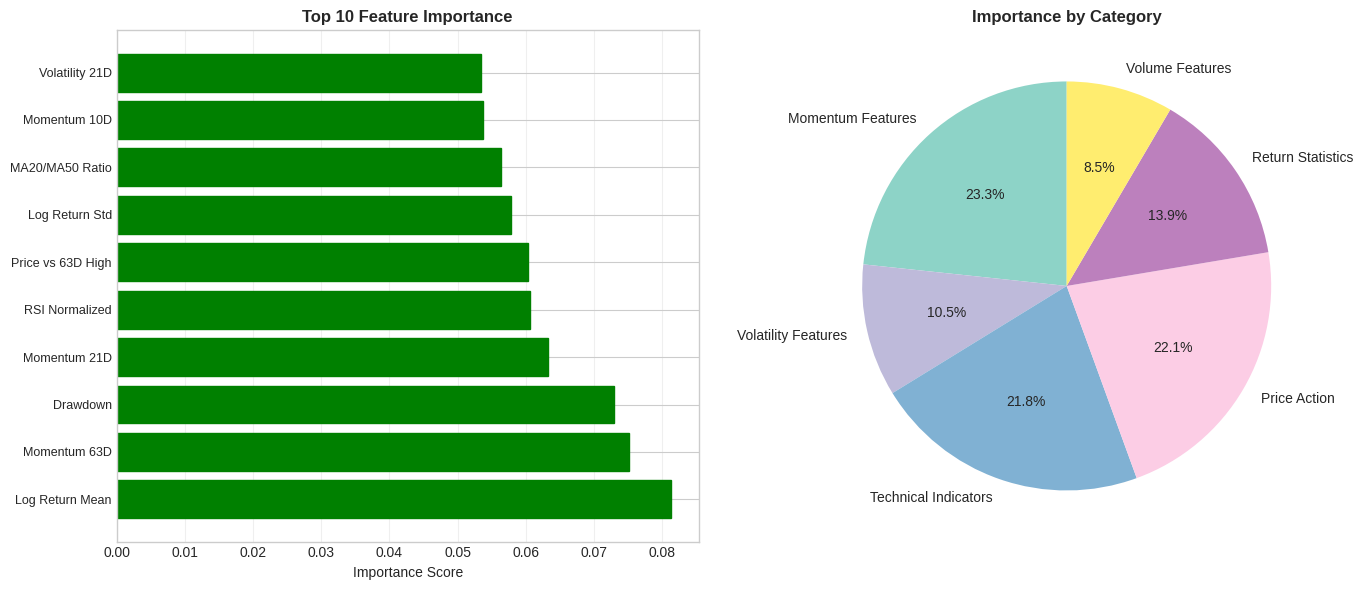


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. TOWR: 0.723%
  2. MDKA: 0.721%
  3. BMRI: 0.680%
  4. INCO: 0.544%
  5. BBCA: 0.461%
  6. BBRI: 0.395%
  7. ANTM: 0.211%
  8. PGAS: 0.210%
  9. ISAT: 0.200%
 10. KLBF: 0.171%
 11. ASII: 0.170%
 12. BBTN: 0.095%
 13. SIDO: 0.019%
 14. INDF: 0.012%
 15. BBNI: -0.083%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 0
Positive predicted stocks      : 14
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mate

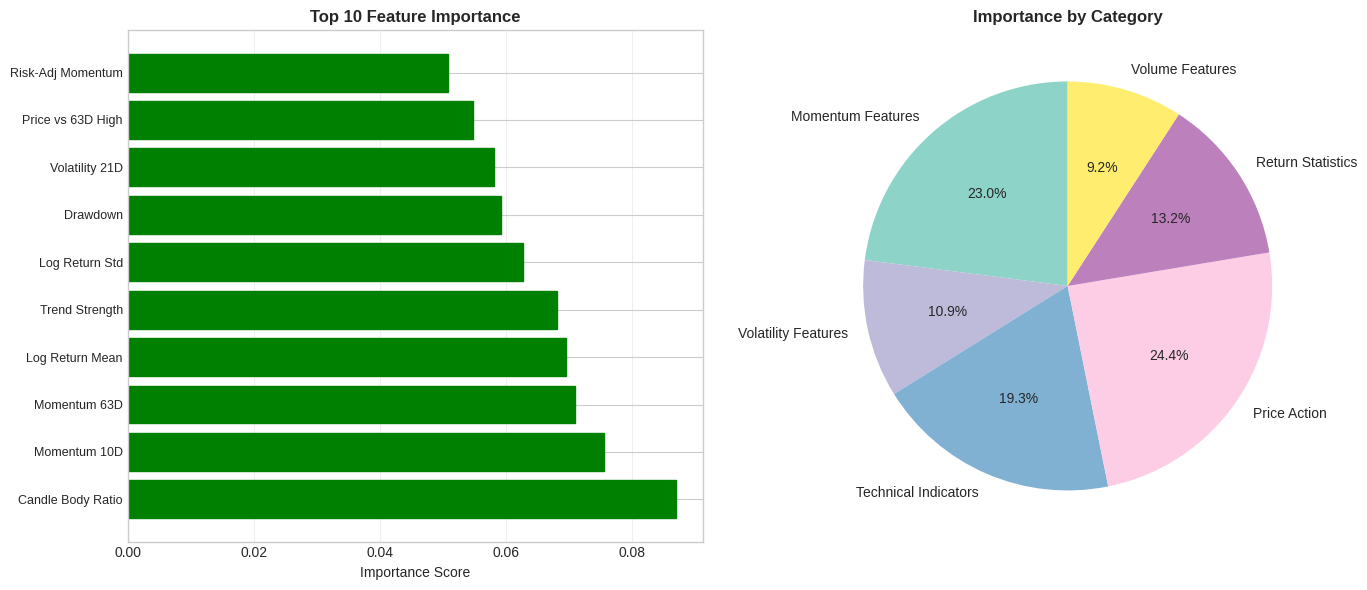


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. BRPT: 19.374%
  2. CTRA: 18.205%
  3. AKRA: 17.311%
  4. BBTN: 17.266%
  5. SMRA: 15.029%
  6. TKIM: 13.219%
  7. INCO: 12.899%
  8. EXCL: 12.783%
  9. INKP: 12.781%
 10. ANTM: 12.042%
 11. PGAS: 11.648%
 12. ISAT: 11.513%
 13. ESSA: 10.736%
 14. ERAA: 10.642%
 15. MEDC: 10.640%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 30
Positive predicted stocks      : 39
Mode                           : BULL
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Se

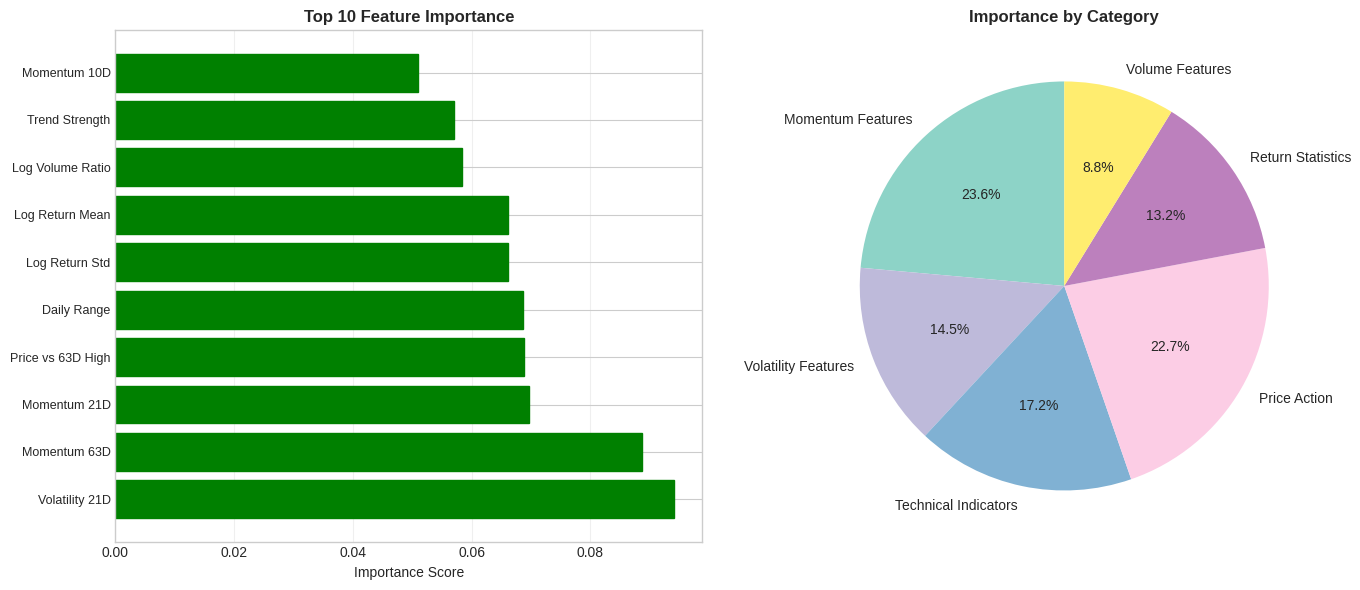


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. TOWR: 5.376%
  2. BBTN: 4.913%
  3. TKIM: 3.334%
  4. INKP: 3.072%
  5. AKRA: 2.949%
  6. MAPA: 2.944%
  7. ESSA: 2.675%
  8. ISAT: 2.543%
  9. INCO: 1.613%
 10. EXCL: 1.509%
 11. ITMG: 1.377%
 12. BMRI: 1.221%
 13. MEDC: 1.190%
 14. BBRI: 1.106%
 15. MDKA: 1.080%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 8
Positive predicted stocks      : 23
Mode                           : BULL
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mater

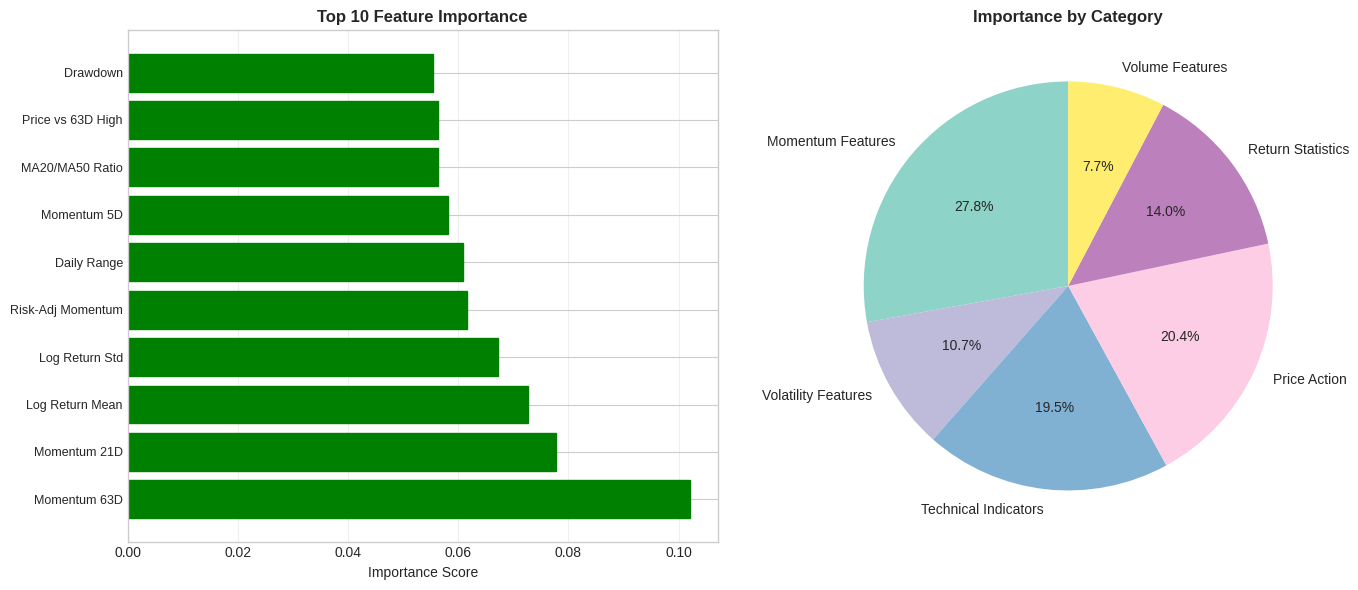


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. BRPT: 5.479%
  2. PGAS: 2.132%
  3. BBTN: 1.822%
  4. MAPA: 1.337%
  5. EMTK: 1.215%
  6. BBRI: 0.811%
  7. MEDC: 0.804%
  8. SMRA: 0.716%
  9. ITMG: 0.715%
 10. JPFA: 0.674%
 11. MDKA: 0.667%
 12. SMGR: 0.486%
 13. BMRI: 0.250%
 14. ESSA: 0.242%
 15. AKRA: 0.192%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 2
Positive predicted stocks      : 16
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Selected after sec

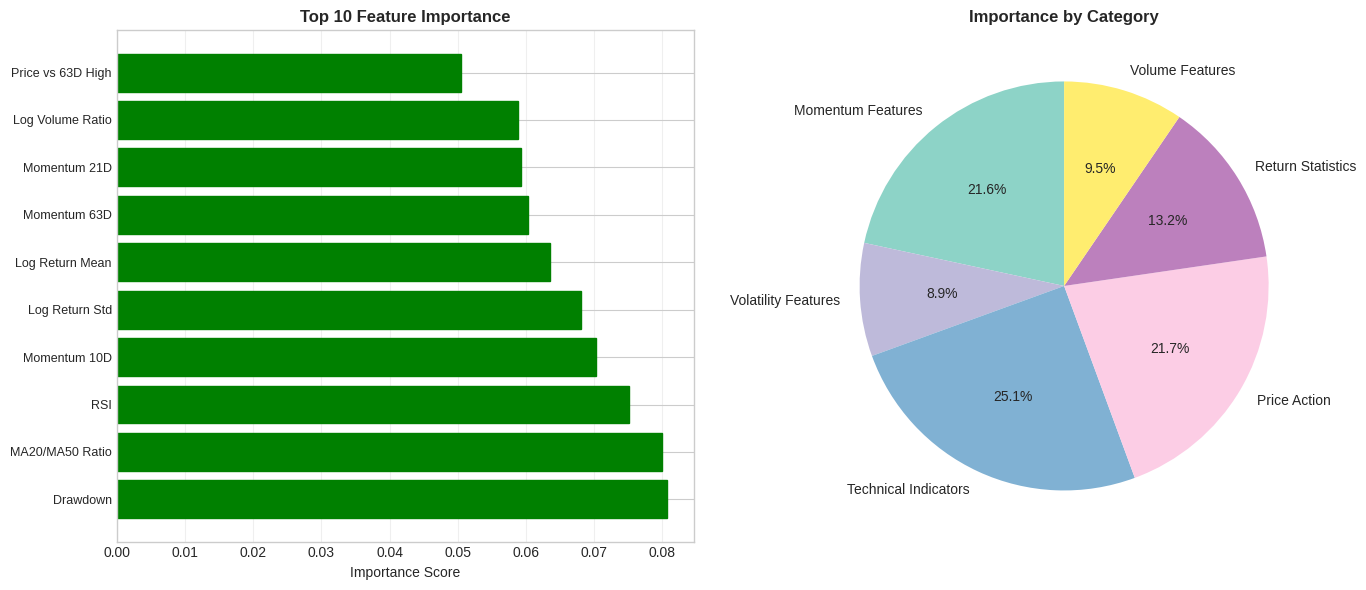


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. ANTM: 13.779%
  2. EMTK: 10.121%
  3. MDKA: 9.592%
  4. HRUM: 5.984%
  5. ESSA: 5.685%
  6. ISAT: 4.742%
  7. MAPA: 1.981%
  8. TKIM: 1.713%
  9. MEDC: 1.380%
 10. SMRA: 1.370%
 11. AKRA: 1.321%
 12. INTP: 1.173%
 13. CPIN: 1.112%
 14. INCO: 0.893%
 15. ASII: 0.774%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 6
Positive predicted stocks      : 31
Mode                           : BULL
Selected before sector filter  : 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mat

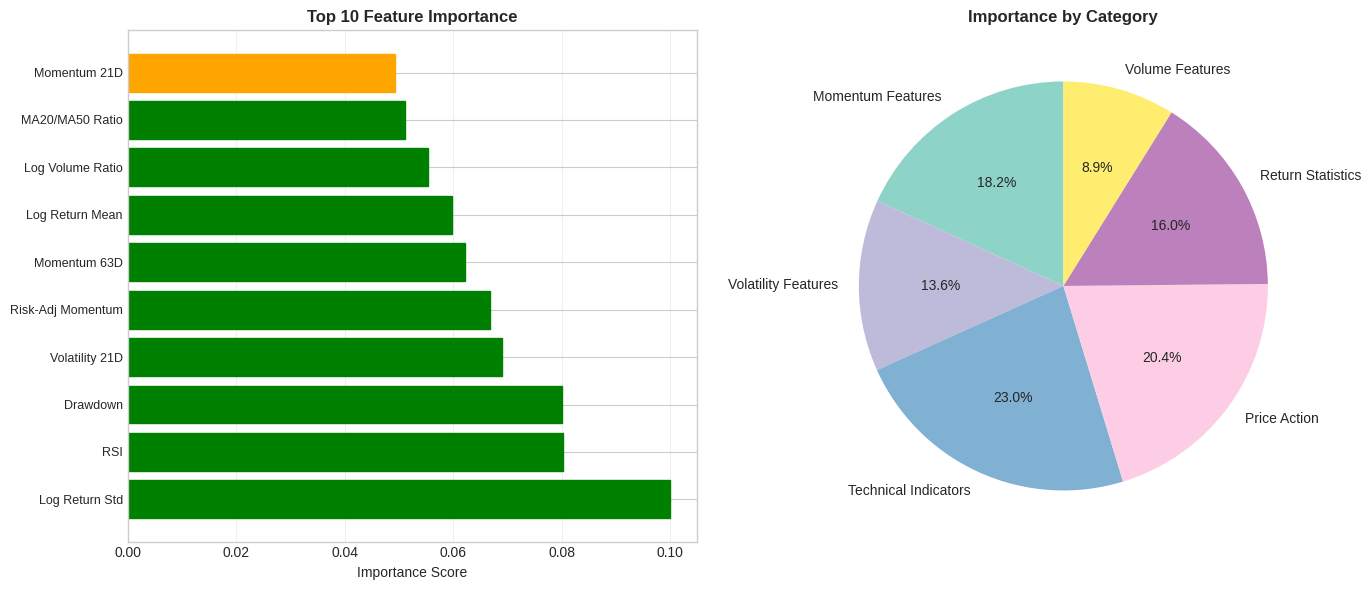


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. ESSA: 7.468%
  2. MAPA: 5.484%
  3. EMTK: 3.187%
  4. ISAT: 2.005%
  5. HRUM: 1.606%
  6. ANTM: 1.566%
  7. TKIM: 1.084%
  8. AKRA: 0.847%
  9. BBTN: 0.735%
 10. PWON: 0.735%
 11. INKP: 0.674%
 12. CPIN: 0.595%
 13. BRPT: 0.594%
 14. MEDC: 0.589%
 15. AMRT: 0.561%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 4
Positive predicted stocks      : 25
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mater

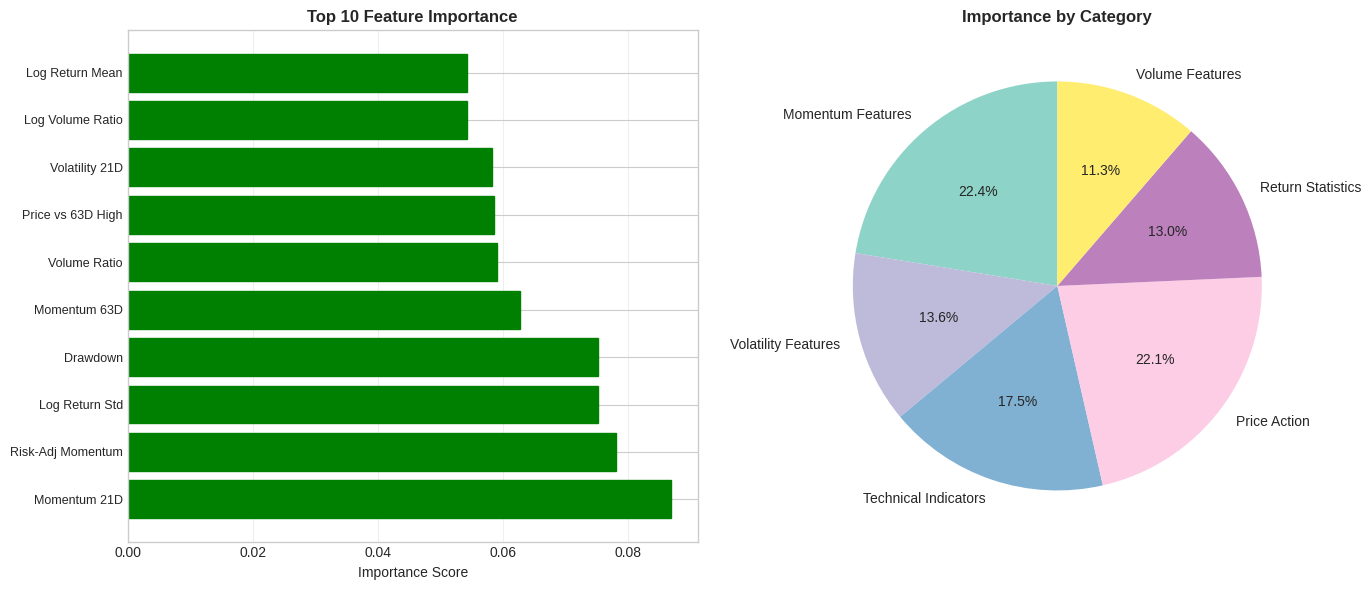


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. MDKA: 2.961%
  2. AMRT: 2.915%
  3. EXCL: 1.165%
  4. TLKM: 1.070%
  5. ITMG: 1.056%
  6. BBTN: 0.979%
  7. ERAA: 0.788%
  8. INCO: 0.717%
  9. TOWR: 0.646%
 10. TKIM: 0.542%
 11. ADRO: 0.533%
 12. BMRI: 0.513%
 13. MEDC: 0.500%
 14. AKRA: 0.425%
 15. ANTM: 0.339%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 2
Positive predicted stocks      : 21
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Selected after sec

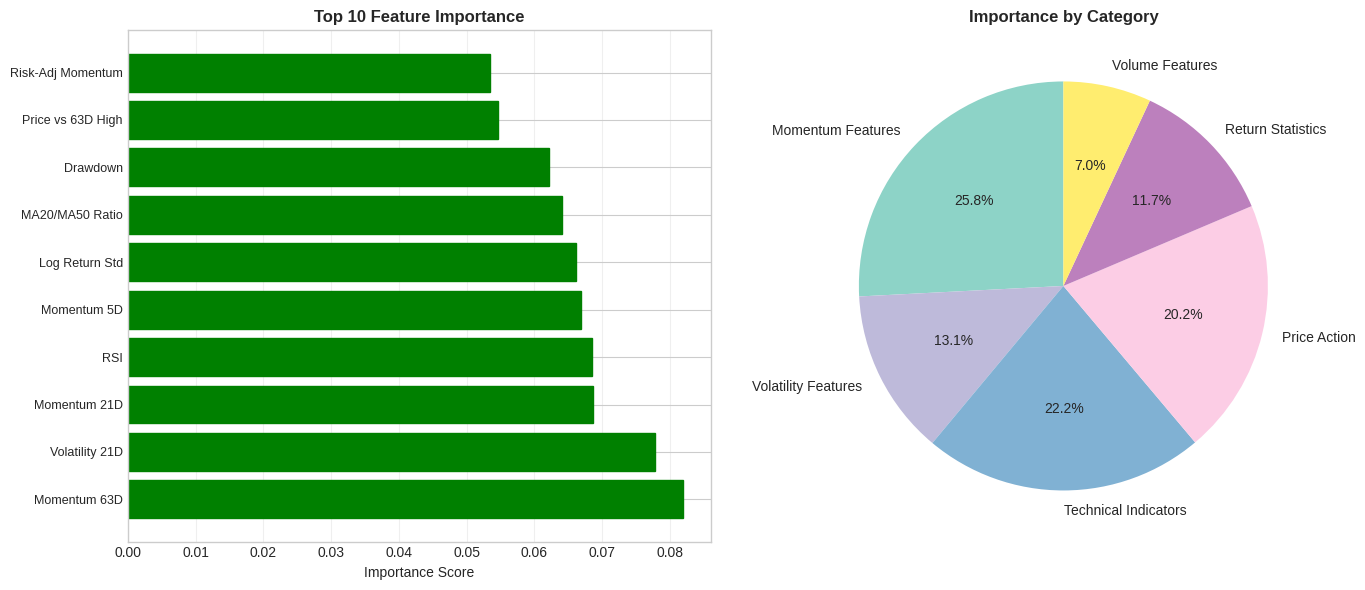


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. MAPA: 5.322%
  2. BBTN: 5.103%
  3. MEDC: 3.580%
  4. PGAS: 3.403%
  5. INKP: 1.705%
  6. UNVR: 1.278%
  7. TKIM: 1.132%
  8. AKRA: 0.884%
  9. INCO: 0.849%
 10. ASII: 0.800%
 11. INTP: 0.793%
 12. BBNI: 0.656%
 13. PWON: 0.651%
 14. PTBA: 0.503%
 15. ANTM: 0.467%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 4
Positive predicted stocks      : 22
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Energy >30%

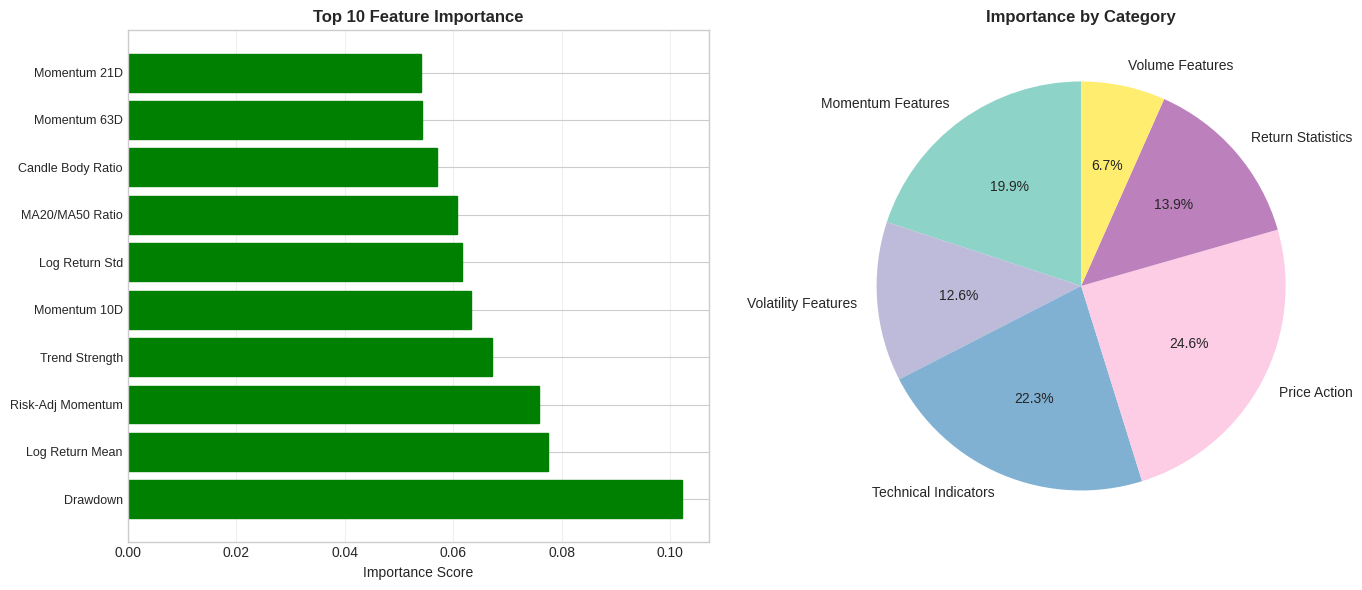


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. MDKA: 3.364%
  2. ADRO: 2.800%
  3. EMTK: 2.765%
  4. HRUM: 2.379%
  5. BBTN: 2.045%
  6. UNVR: 1.928%
  7. INTP: 1.830%
  8. AKRA: 1.727%
  9. MIKA: 1.653%
 10. BRPT: 1.628%
 11. PGAS: 1.606%
 12. PWON: 1.548%
 13. TLKM: 1.480%
 14. TKIM: 1.422%
 15. SMRA: 1.418%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 5
Positive predicted stocks      : 41
Mode                           : BULL
Selected before sector filter  : 5

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Energy >30%

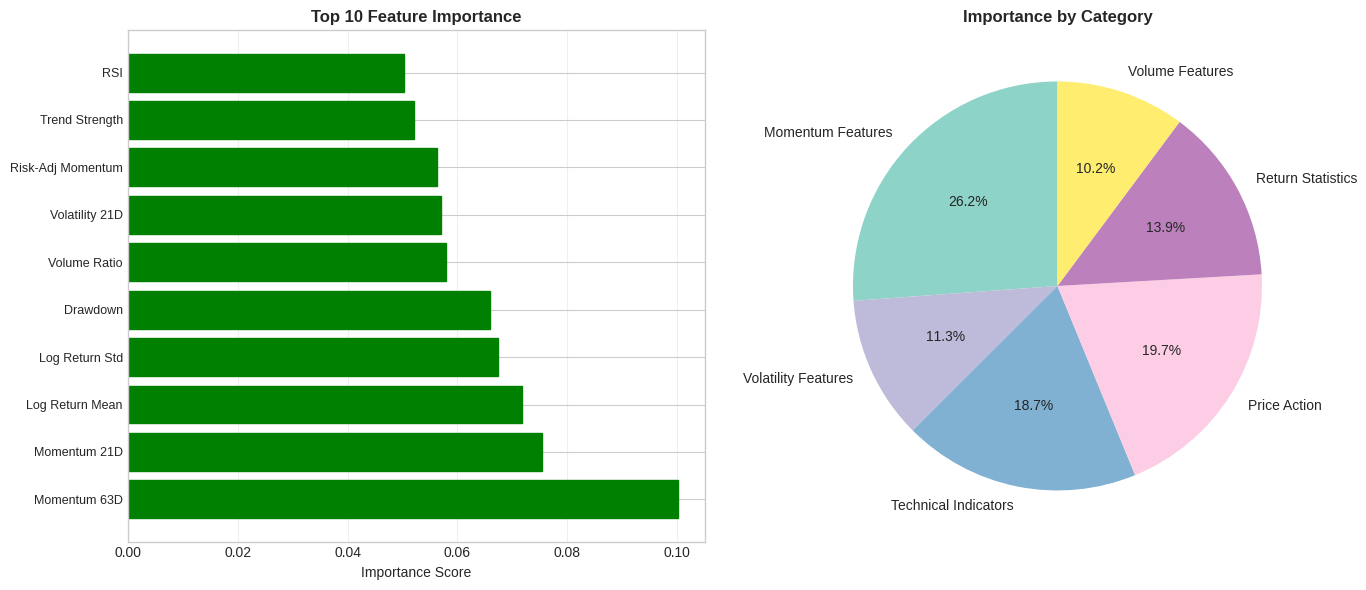


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. ESSA: 9.216%
  2. UNVR: 7.006%
  3. MAPA: 1.114%
  4. PGAS: 0.874%
  5. INKP: 0.751%
  6. PTBA: 0.691%
  7. TKIM: 0.560%
  8. ITMG: -0.185%
  9. MDKA: -0.348%
 10. MEDC: -0.527%
 11. AMRT: -0.649%
 12. INCO: -0.650%
 13. SIDO: -0.782%
 14. BRPT: -0.790%
 15. BBTN: -0.804%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 2
Positive predicted stocks      : 7
Mode                           : BEAR
Selected before sector filter  : 7

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basi

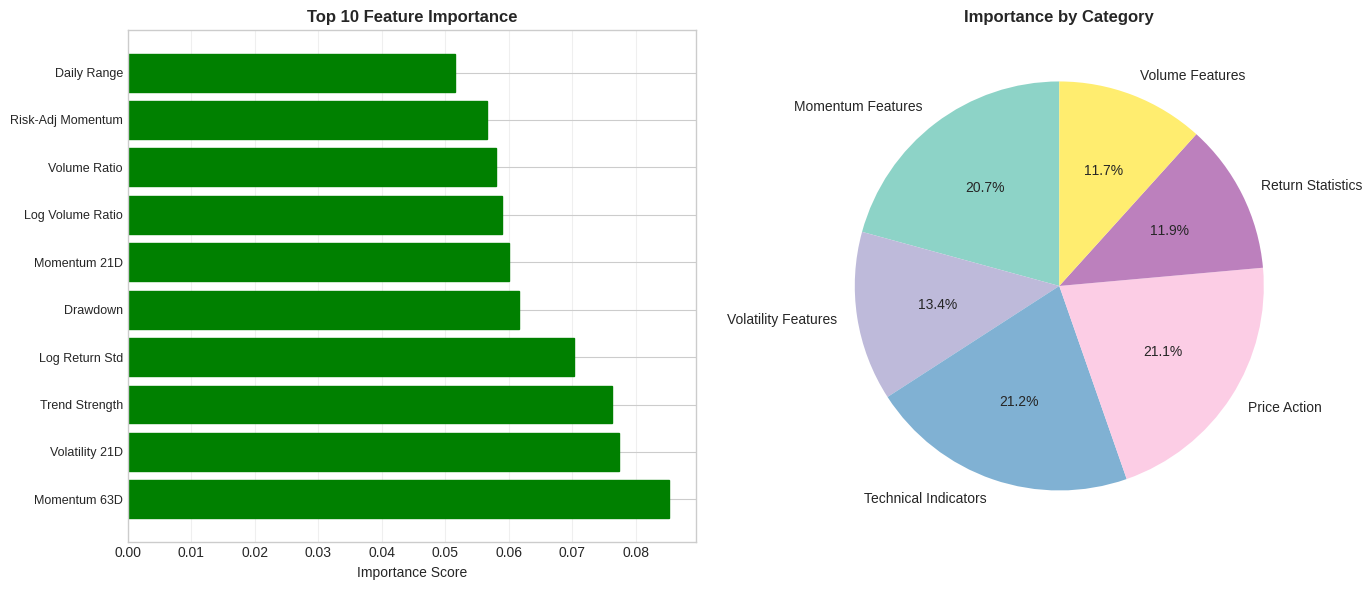


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. INKP: 3.546%
  2. MAPA: 2.833%
  3. TKIM: 2.576%
  4. PTBA: 2.166%
  5. ITMG: 2.156%
  6. MEDC: 2.117%
  7. PGAS: 1.950%
  8. INDF: 1.791%
  9. ICBP: 1.718%
 10. ISAT: 1.557%
 11. UNTR: 1.549%
 12. PWON: 1.508%
 13. SMGR: 1.486%
 14. EXCL: 1.478%
 15. ASII: 1.335%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 6
Positive predicted stocks      : 42
Mode                           : BULL
Selected before sector filter  : 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mater

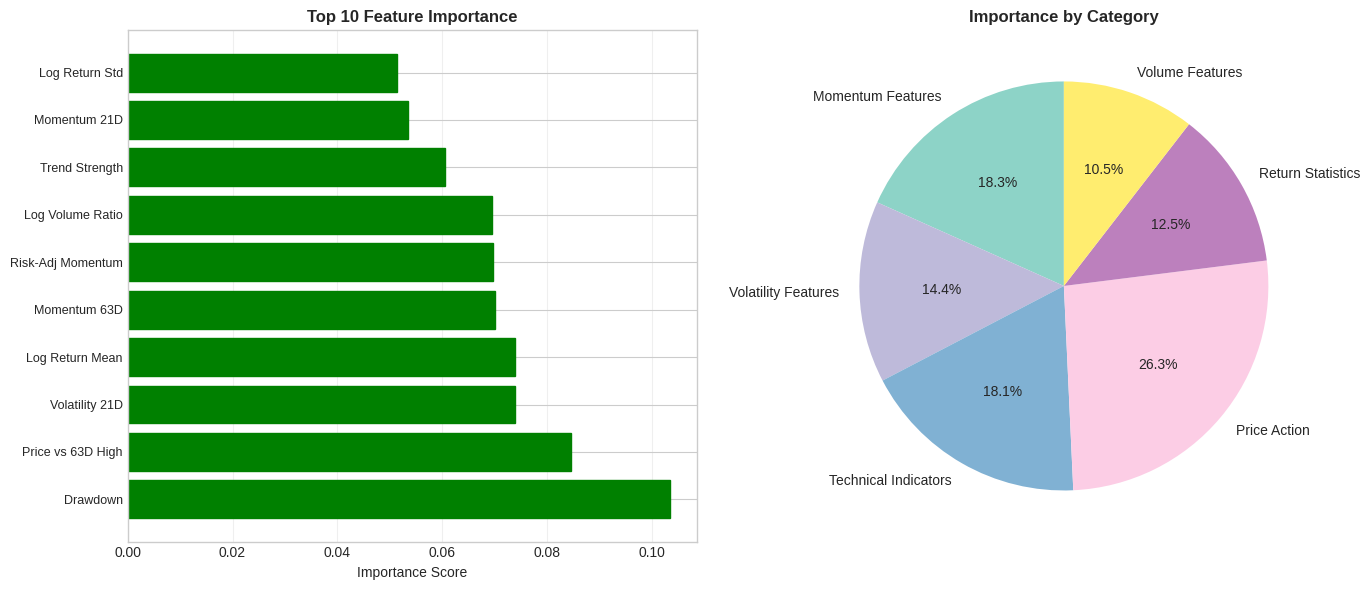


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. TKIM: 27.710%
  2. INKP: 4.898%
  3. MEDC: 3.638%
  4. MAPA: 3.500%
  5. BUKA: 3.166%
  6. INCO: 3.098%
  7. HRUM: 2.999%
  8. BBTN: 2.604%
  9. PGAS: 2.107%
 10. MDKA: 1.839%
 11. ADRO: 1.814%
 12. UNVR: 1.803%
 13. ISAT: 1.744%
 14. EXCL: 1.714%
 15. BMRI: 1.675%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 9
Positive predicted stocks      : 43
Mode                           : BULL
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mate

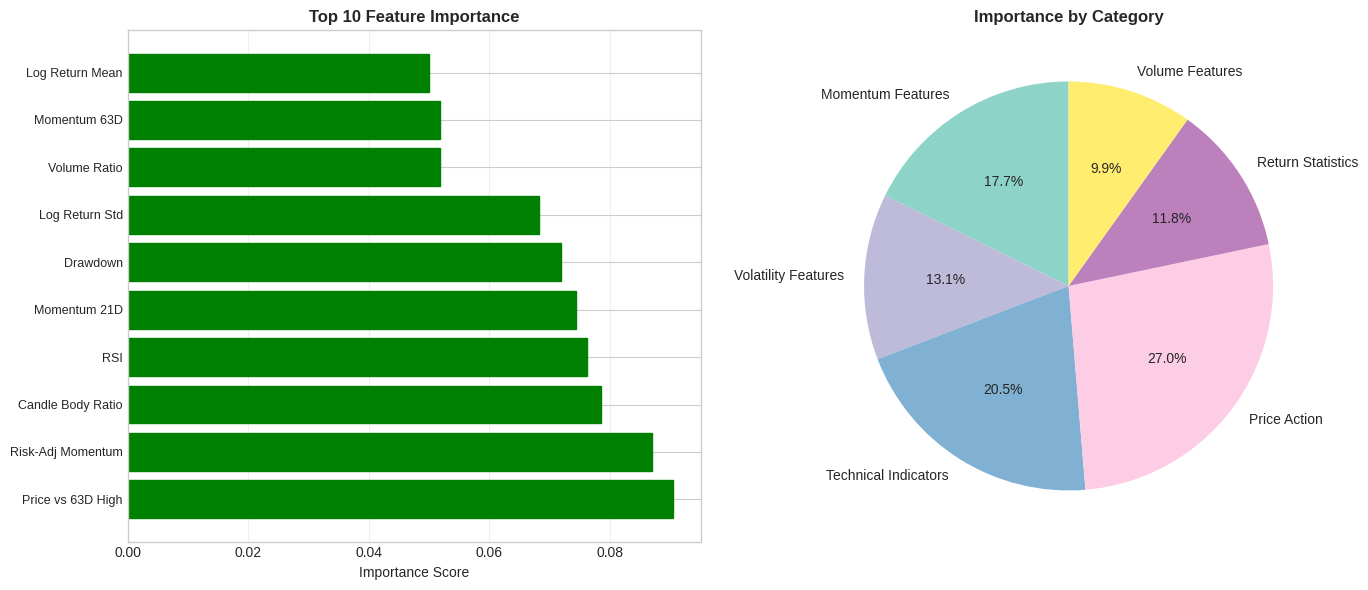


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. CTRA: 1.634%
  2. BUKA: 1.597%
  3. SMRA: 1.246%
  4. PWON: 1.227%
  5. MDKA: 1.130%
  6. INTP: 1.098%
  7. TKIM: 0.972%
  8. UNVR: 0.915%
  9. SIDO: 0.874%
 10. BBCA: 0.861%
 11. JPFA: 0.815%
 12. KLBF: 0.774%
 13. EMTK: 0.736%
 14. INKP: 0.728%
 15. CPIN: 0.647%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 0
Positive predicted stocks      : 35
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Properties 

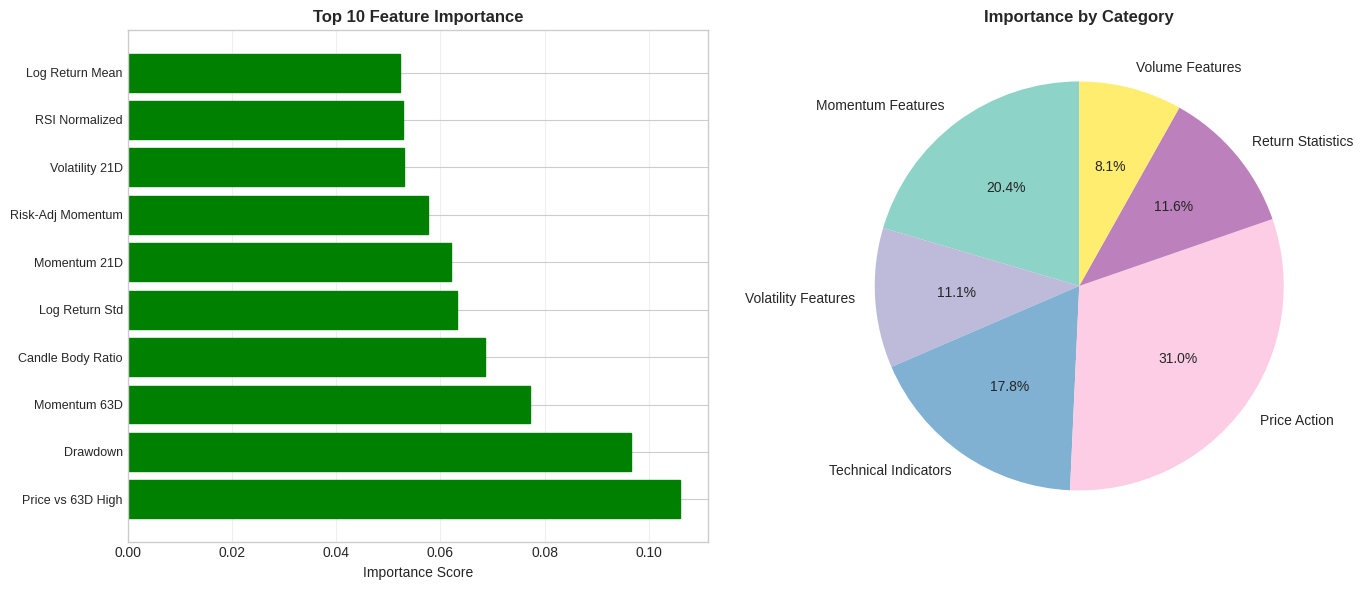


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. TKIM: 2.544%
  2. MEDC: 1.074%
  3. BRPT: 0.990%
  4. BBTN: 0.890%
  5. MAPA: 0.677%
  6. INTP: 0.580%
  7. SIDO: 0.508%
  8. ISAT: 0.442%
  9. SMGR: 0.360%
 10. AMRT: 0.297%
 11. KLBF: 0.251%
 12. EXCL: 0.206%
 13. MDKA: 0.185%
 14. INKP: 0.177%
 15. ANTM: 0.172%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 1
Positive predicted stocks      : 18
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mater

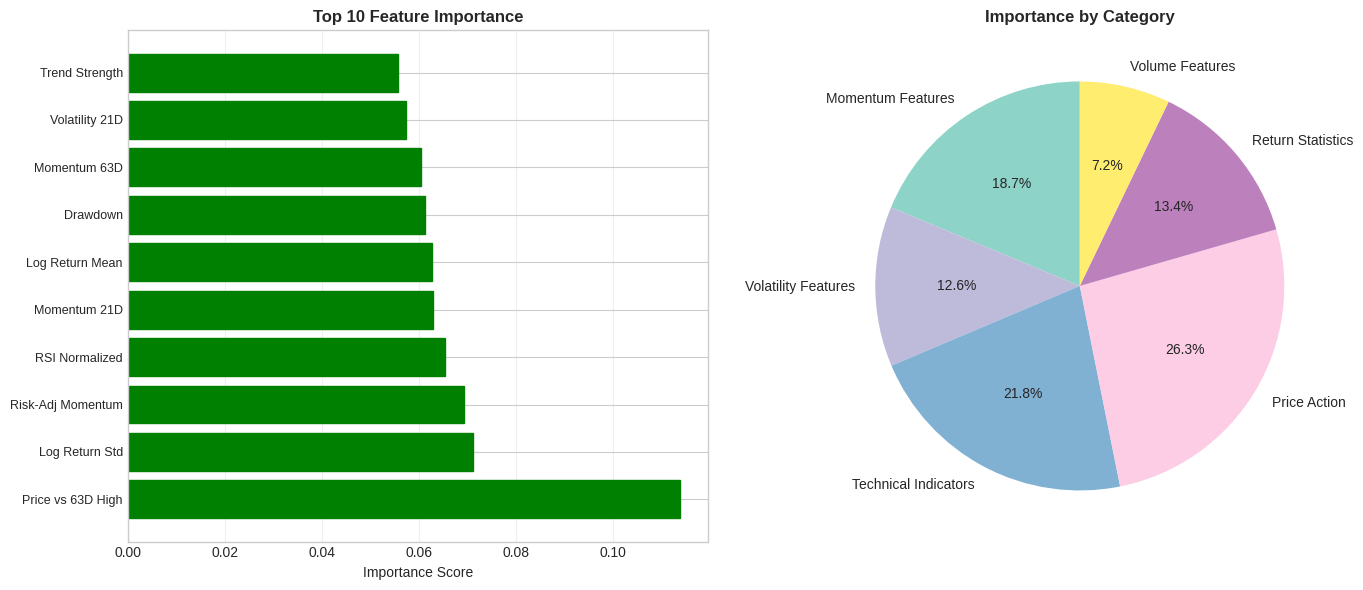


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. JPFA: 6.076%
  2. ESSA: 5.478%
  3. GOTO: 5.129%
  4. EMTK: 4.632%
  5. CPIN: 4.218%
  6. SMGR: 3.968%
  7. SMRA: 3.597%
  8. BBTN: 3.592%
  9. EXCL: 3.503%
 10. MDKA: 3.436%
 11. UNVR: 3.435%
 12. ICBP: 3.423%
 13. INKP: 3.183%
 14. INTP: 2.918%
 15. TOWR: 2.825%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 29
Positive predicted stocks      : 44
Mode                           : BULL
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Selected after se

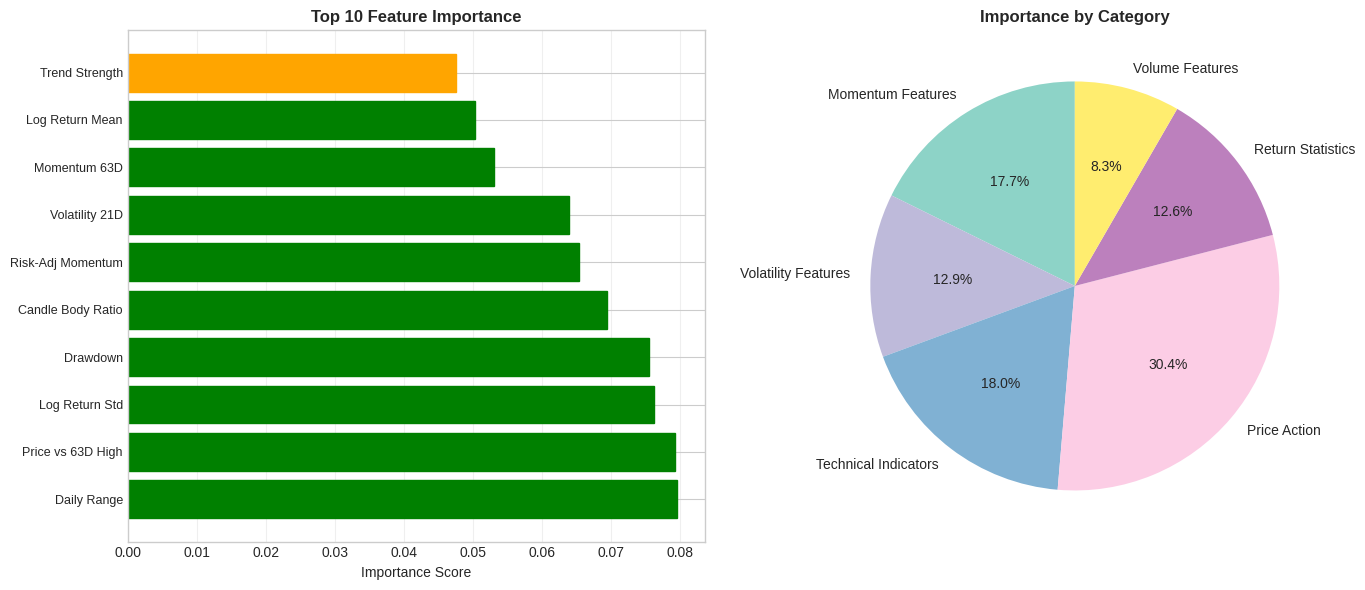


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. EMTK: 1.798%
  2. TKIM: 1.774%
  3. UNVR: 1.646%
  4. EXCL: 1.549%
  5. INKP: 1.533%
  6. PGAS: 1.351%
  7. JPFA: 1.198%
  8. MAPA: 1.170%
  9. AMRT: 1.041%
 10. SMGR: 0.968%
 11. INTP: 0.932%
 12. UNTR: 0.918%
 13. BRPT: 0.907%
 14. SMRA: 0.899%
 15. ITMG: 0.898%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 0
Positive predicted stocks      : 41
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Selected after sec

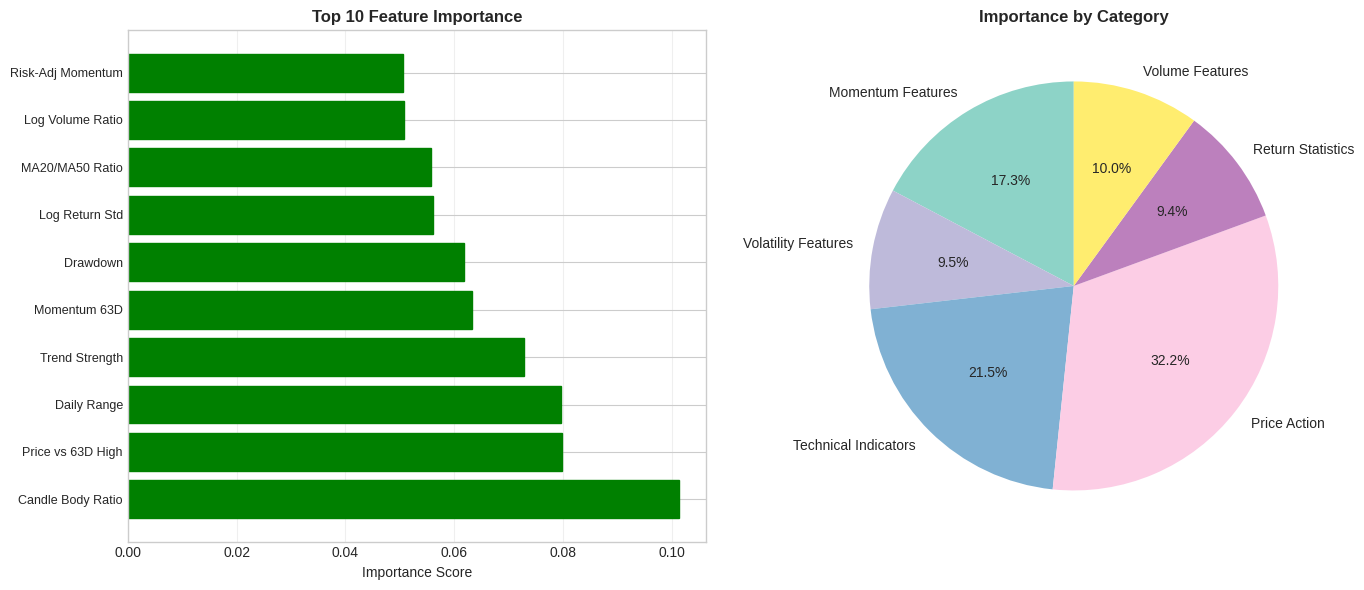


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. BBTN: 4.195%
  2. GOTO: 2.697%
  3. SMRA: 1.353%
  4. EMTK: 1.214%
  5. UNVR: 1.210%
  6. JPFA: 1.166%
  7. SMGR: 0.997%
  8. INTP: 0.954%
  9. CTRA: 0.883%
 10. PGAS: 0.763%
 11. ERAA: 0.649%
 12. AKRA: 0.645%
 13. BUKA: 0.535%
 14. MEDC: 0.475%
 15. SIDO: 0.471%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 2
Positive predicted stocks      : 35
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Selected after sec

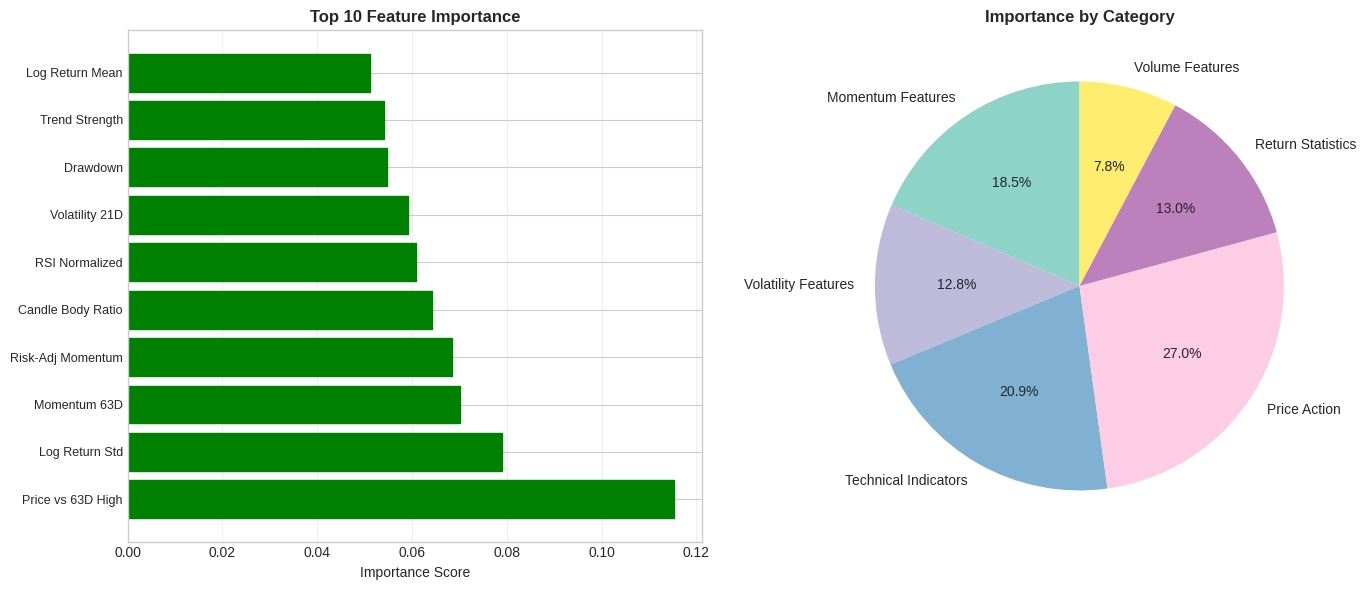


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. BRPT: 1.959%
  2. TKIM: 1.782%
  3. BBTN: 1.772%
  4. UNVR: 1.561%
  5. INCO: 1.395%
  6. BMRI: 1.367%
  7. EXCL: 1.298%
  8. ISAT: 1.185%
  9. PGAS: 1.165%
 10. AKRA: 1.133%
 11. MAPA: 1.097%
 12. BBNI: 1.081%
 13. BBRI: 1.064%
 14. INKP: 1.044%
 15. ERAA: 0.959%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 0
Positive predicted stocks      : 42
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mater

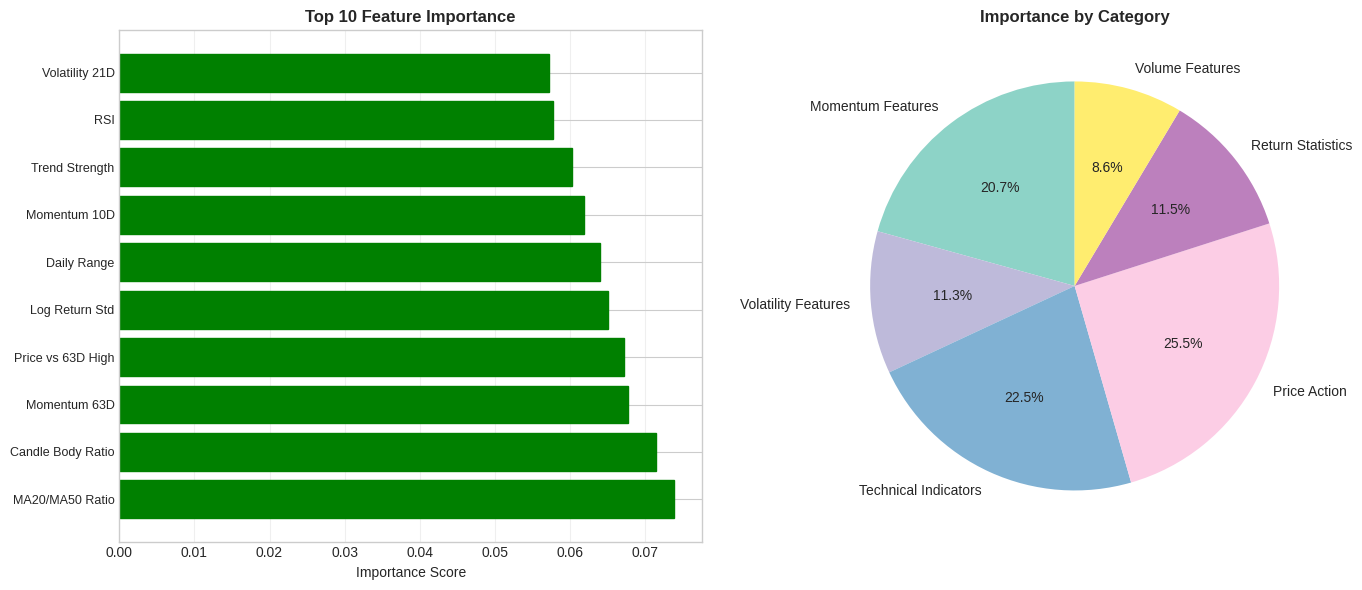


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. UNVR: 1.649%
  2. EMTK: 1.607%
  3. SMRA: 1.279%
  4. TKIM: 1.241%
  5. JPFA: 1.214%
  6. EXCL: 1.045%
  7. PGAS: 1.008%
  8. INCO: 0.990%
  9. ESSA: 0.978%
 10. SIDO: 0.949%
 11. BBTN: 0.823%
 12. INKP: 0.775%
 13. HRUM: 0.724%
 14. BUKA: 0.696%
 15. BMRI: 0.631%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 0
Positive predicted stocks      : 34
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Selected after sec

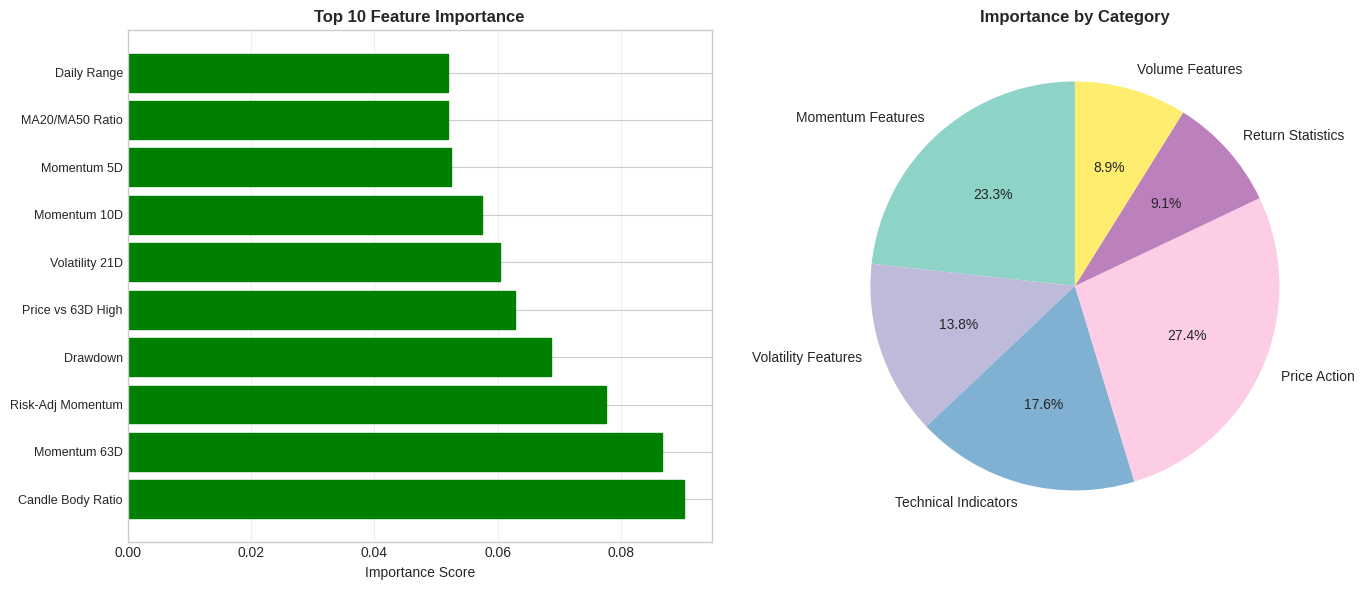


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. INTP: 2.334%
  2. TOWR: 1.849%
  3. SMGR: 1.540%
  4. INKP: 1.199%
  5. ICBP: 1.088%
  6. EMTK: 1.040%
  7. ADRO: 1.037%
  8. SMRA: 0.904%
  9. ERAA: 0.858%
 10. BBNI: 0.851%
 11. INDF: 0.806%
 12. BBTN: 0.803%
 13. TKIM: 0.786%
 14. PWON: 0.781%
 15. PTBA: 0.766%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 1
Positive predicted stocks      : 39
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mater

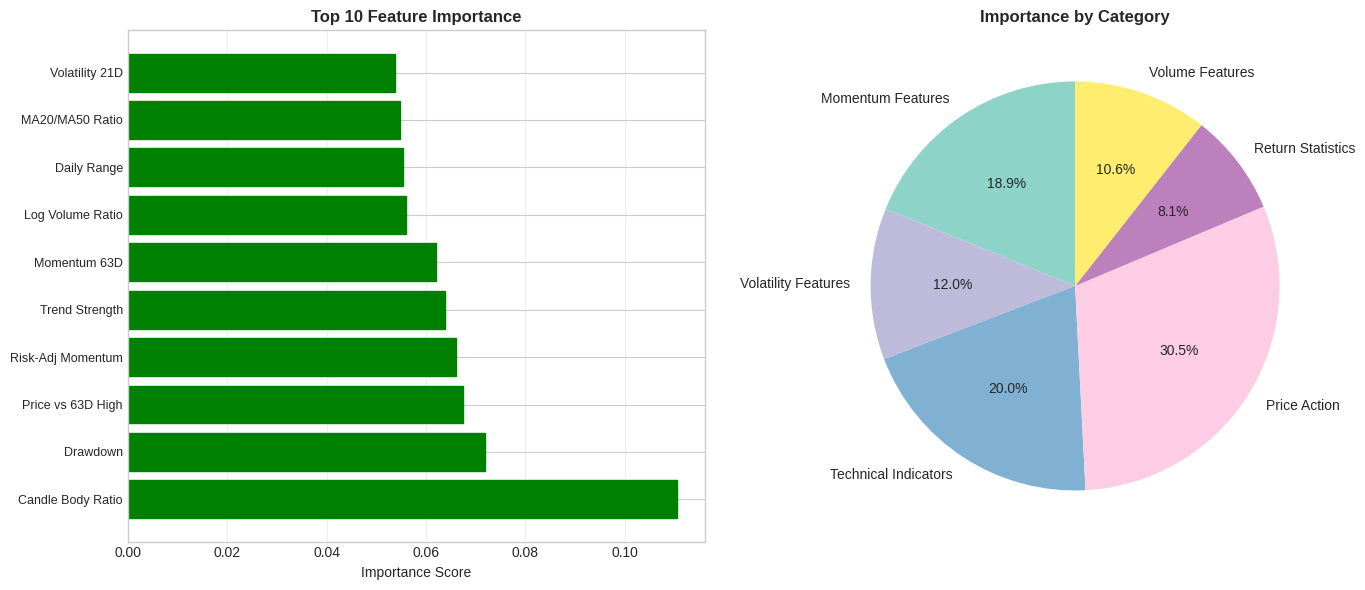


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. INTP: 2.125%
  2. CPIN: 0.729%
  3. INDF: 0.704%
  4. ANTM: 0.697%
  5. UNTR: 0.640%
  6. JPFA: 0.634%
  7. UNVR: 0.592%
  8. MAPA: 0.551%
  9. PGAS: 0.511%
 10. AMRT: 0.444%
 11. BBTN: 0.262%
 12. MIKA: 0.239%
 13. ERAA: 0.195%
 14. ESSA: 0.158%
 15. AKRA: 0.144%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 1
Positive predicted stocks      : 19
Mode                           : BEAR
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Consumer No

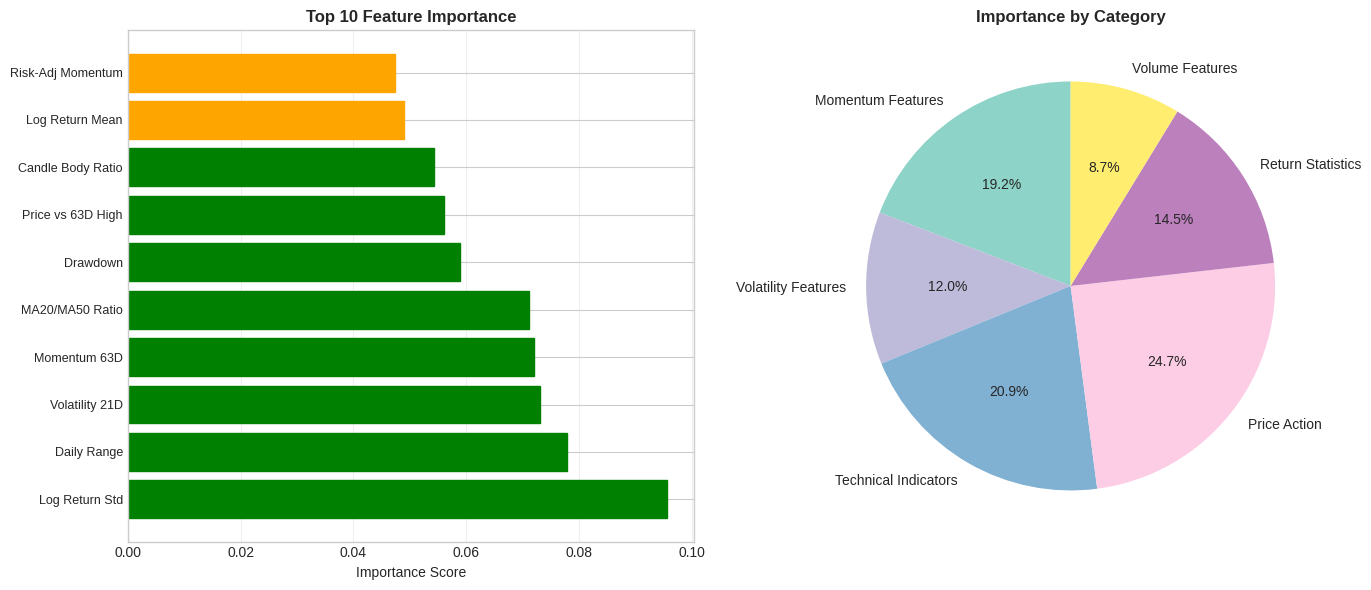


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. TKIM: 3.065%
  2. INKP: 2.771%
  3. UNVR: 2.465%
  4. MDKA: 2.298%
  5. INTP: 2.293%
  6. ANTM: 1.956%
  7. SMRA: 1.690%
  8. PWON: 1.494%
  9. INCO: 1.449%
 10. BBTN: 1.398%
 11. TOWR: 1.374%
 12. BRPT: 1.349%
 13. EXCL: 1.339%
 14. MEDC: 1.243%
 15. AKRA: 1.242%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 5
Positive predicted stocks      : 42
Mode                           : BULL
Selected before sector filter  : 5

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mater

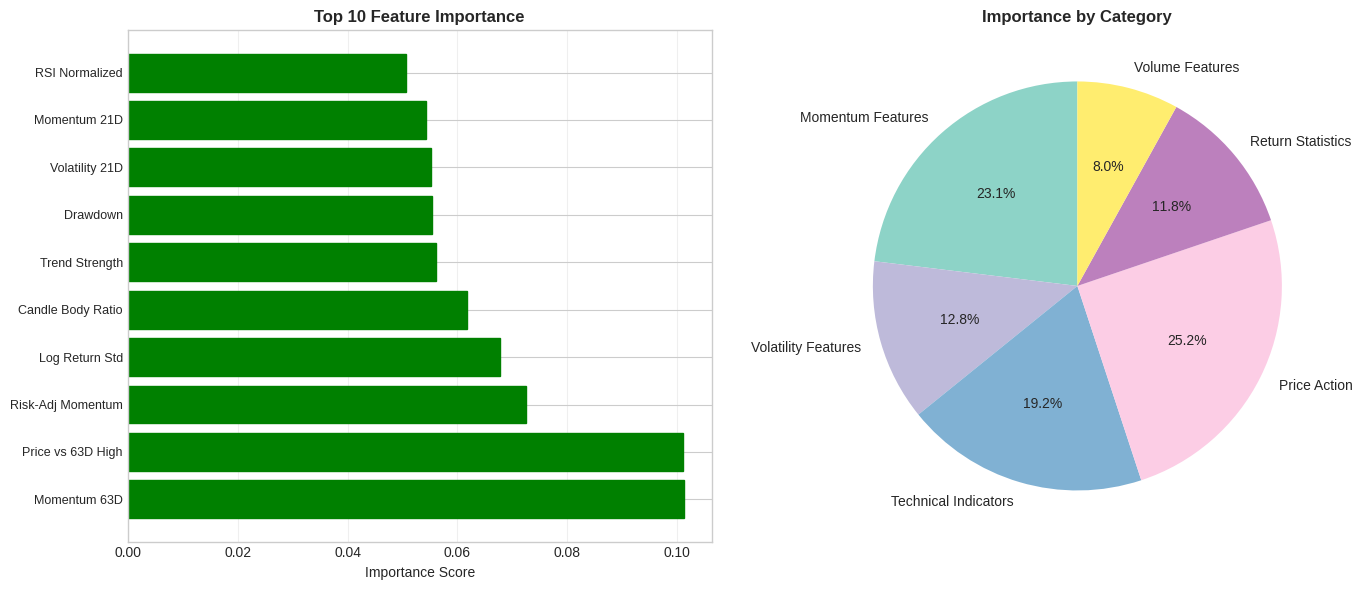


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. INCO: 6.822%
  2. BRPT: 6.766%
  3. MAPA: 6.261%
  4. ERAA: 5.880%
  5. AMRT: 5.583%
  6. HRUM: 5.469%
  7. ISAT: 5.447%
  8. UNVR: 5.099%
  9. ANTM: 4.982%
 10. AMMN: 4.477%
 11. BUKA: 3.839%
 12. INTP: 3.780%
 13. AKRA: 3.570%
 14. SMGR: 3.560%
 15. MDKA: 3.495%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 29
Positive predicted stocks      : 45
Mode                           : BULL
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Selected after se

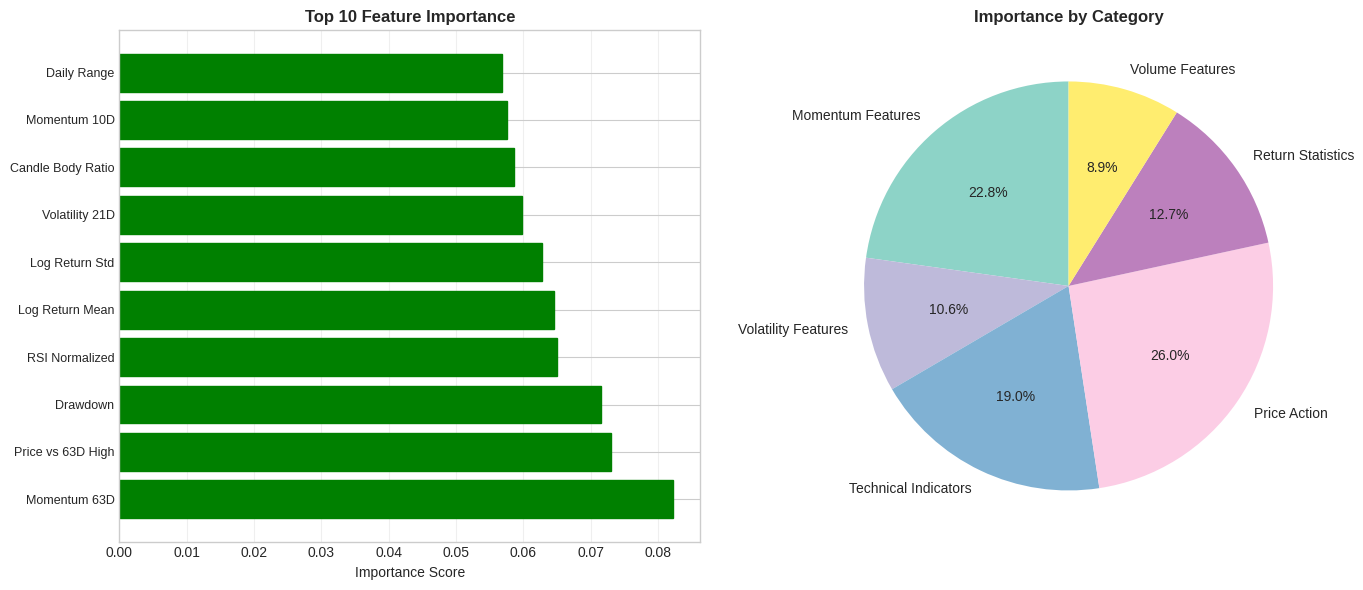


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. EMTK: 15.837%
  2. TKIM: 8.270%
  3. BRPT: 7.452%
  4. INKP: 7.166%
  5. UNVR: 7.160%
  6. HRUM: 6.216%
  7. SMRA: 5.763%
  8. INTP: 5.680%
  9. BUKA: 5.546%
 10. UNTR: 5.431%
 11. PWON: 5.291%
 12. GOTO: 5.076%
 13. BBTN: 4.988%
 14. ASII: 4.952%
 15. SIDO: 4.668%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 45
Positive predicted stocks      : 45
Mode                           : BULL
Selected before sector filter  : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Basic Mat

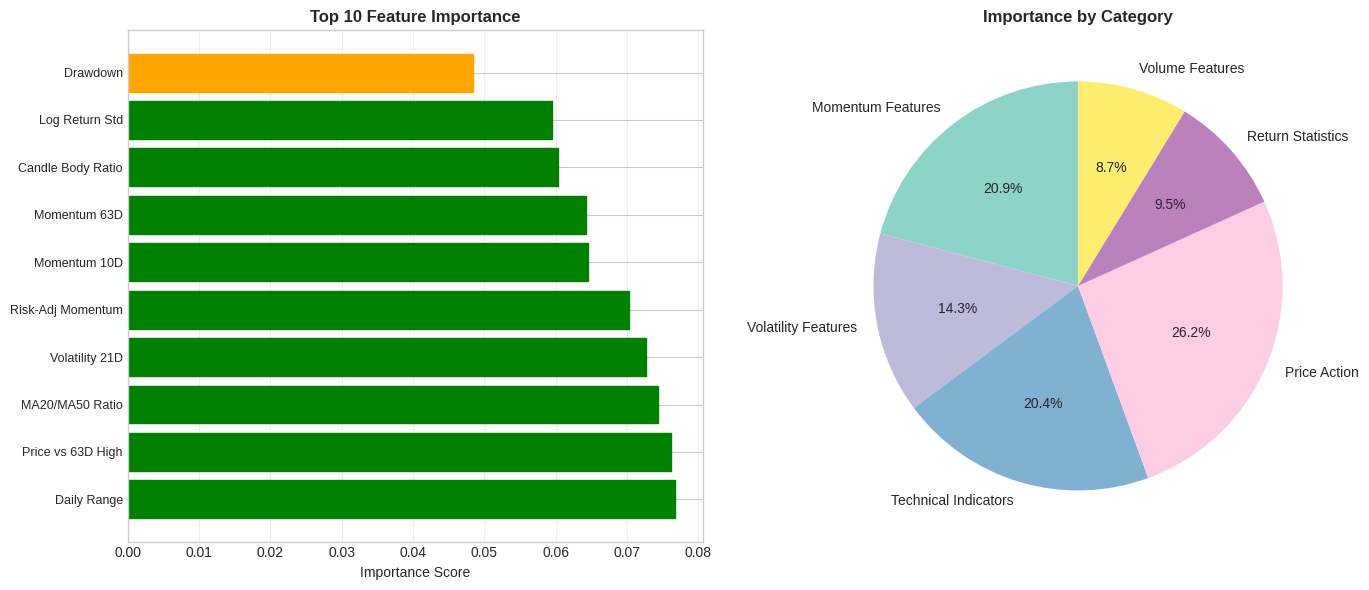


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns (Top 15)
------------------------------------------------------------
  1. SIDO: 2.549%
  2. UNVR: 2.422%
  3. BRPT: 2.263%
  4. INKP: 2.167%
  5. BUKA: 2.150%
  6. INTP: 1.898%
  7. TKIM: 1.874%
  8. MDKA: 1.770%
  9. BBCA: 1.719%
 10. ISAT: 1.686%
 11. GOTO: 1.683%
 12. SMGR: 1.585%
 13. BBTN: 1.578%
 14. JPFA: 1.515%
 15. MAPA: 1.384%

STOCK SELECTION
------------------------------------------------------------
Return threshold               : 2.0%
Bull min candidates            : 5
Max portfolio stocks           : 8
Bull max weight                : 25.0%
Bear max weight                : 12.5%
Stocks above threshold         : 5
Positive predicted stocks      : 43
Mode                           : BULL
Selected before sector filter  : 5

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Consumer No

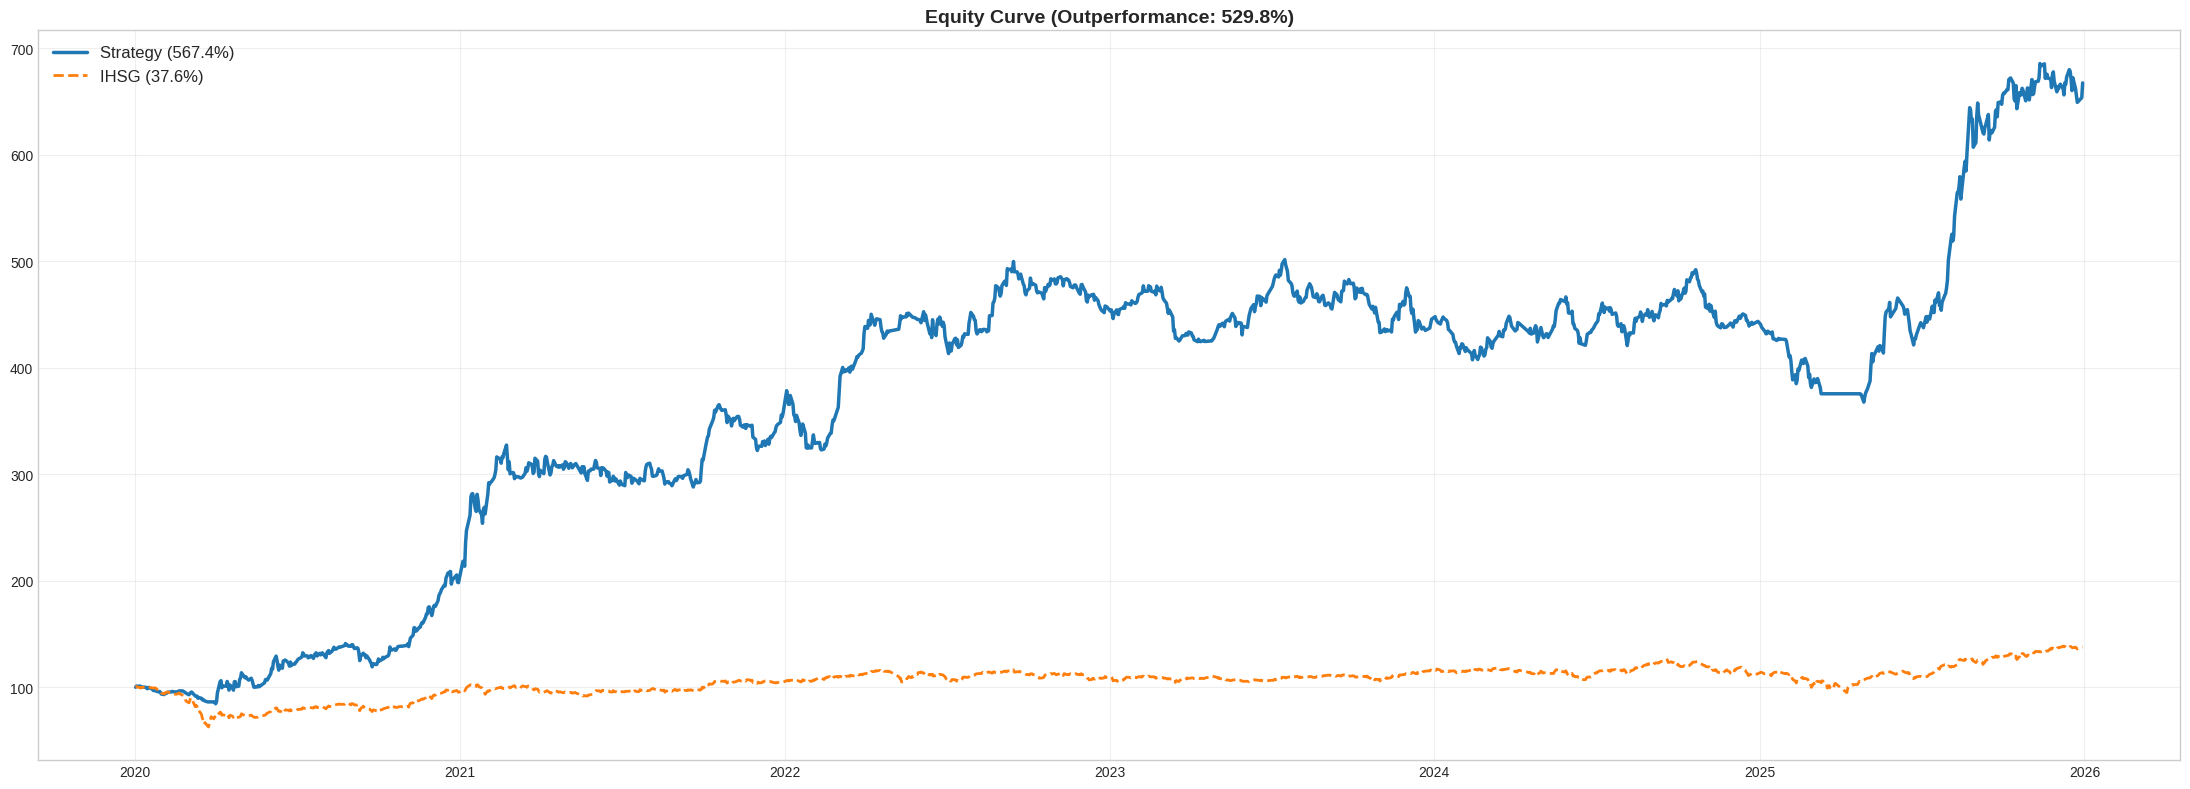

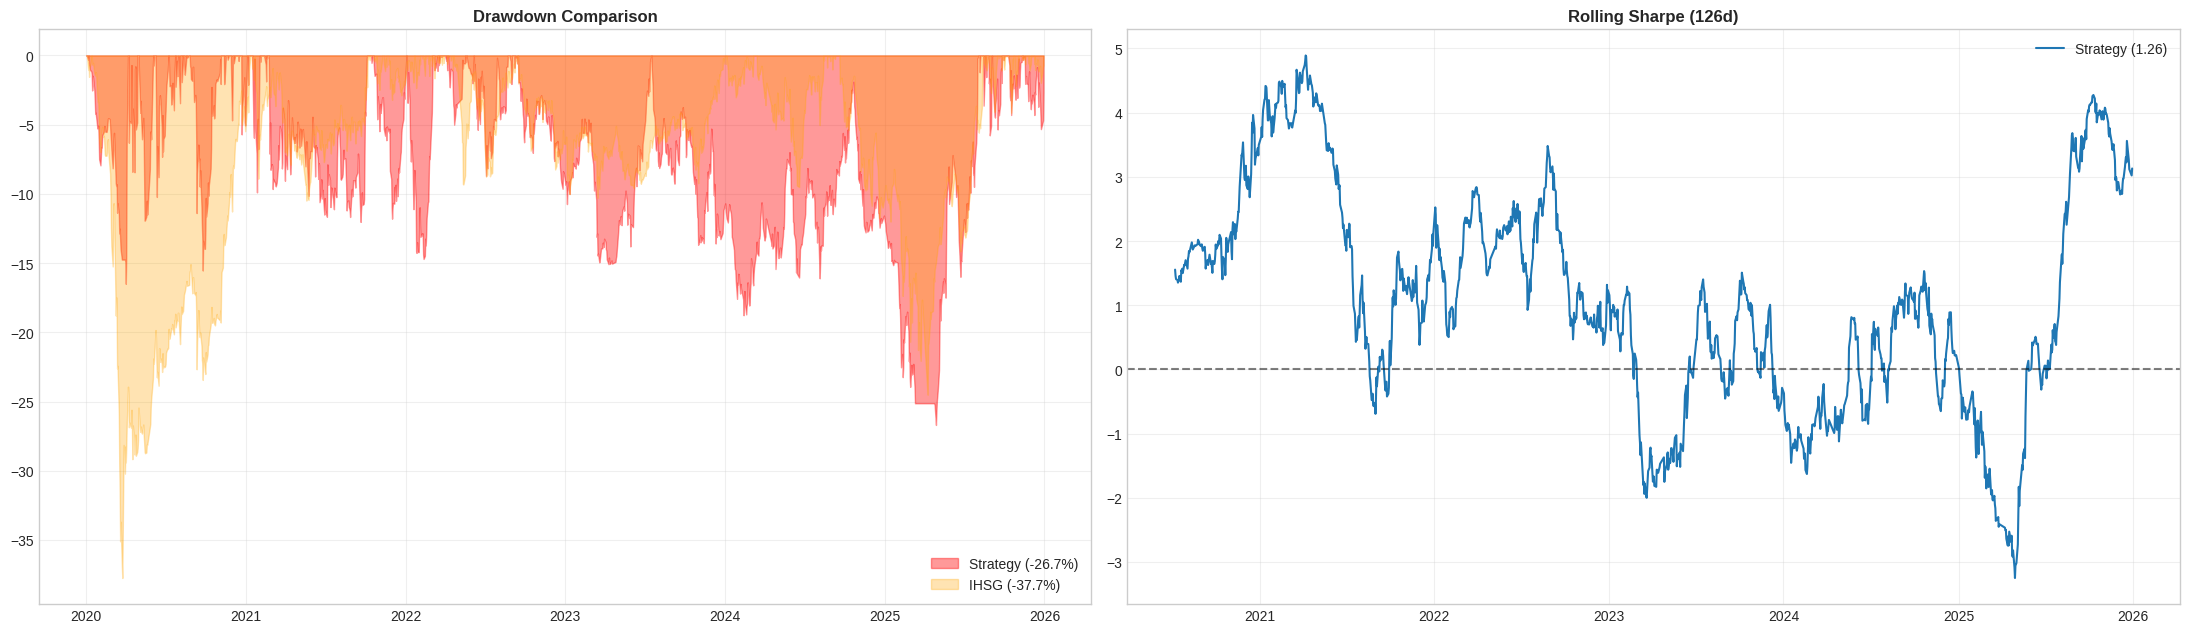


BACKTEST COMPLETED
Final Portfolio Value: Rp 666,092,274
Initial Investment: Rp 99,800,417
Total Gain: Rp 566,291,857


In [17]:
# Run backtest
print("BACKTEST RUN")

results = recommender.run_backtest(
    BACKTEST_START,
    BACKTEST_STOP,
    freq=REBAL_FREQ
)

print("\nBACKTEST COMPLETED")
print(f"Final Portfolio Value: Rp {results.iloc[-1]:,.0f}")
print(f"Initial Investment: Rp {results.iloc[0]:,.0f}")
print(f"Total Gain: Rp {results.iloc[-1] - results.iloc[0]:,.0f}")

## Cell 18: Display XAI Insights

In [18]:
# Print comprehensive XAI summary
recommender.print_xai_summary()


XAI SUMMARY ACROSS REBALANCES

FEATURE CATEGORY ANALYSIS (AVERAGE):
------------------------------------------------------------------------------------------
Category                  Contribution (%)          Top Indicators
------------------------------------------------------------------------------------------
Price Action              25.0%                     Price vs 63D High, Drawdown
Momentum Features         21.2%                     Momentum 63D, Momentum 21D
Technical Indicators      20.2%                     Trend Strength, MA20/MA50 Ratio
Return Statistics         12.4%                     Log Return Std, Log Return Mean
Volatility Features       12.3%                     Risk-Adj Momentum, Volatility 21D
Volume Features           8.9%                      Log Volume Ratio, Volume Ratio

MOST COMMON STOCK CATEGORIES:
 - Near High / Breakout: 71 selections (23.9%)
 - High Volatility: 68 selections (22.9%)
 - High Momentum: 66 selections (22.2%)
 - Negative Momentum: 43 s

## Cell 19: Export Results

In [19]:
# Export results to CSV
results_df = results.to_frame('Portfolio Value')
results_df['Return %'] = results_df['Portfolio Value'].pct_change() * 100
results_df['Cumulative Return %'] = ((results_df['Portfolio Value'] / results_df['Portfolio Value'].iloc[0]) - 1) * 100

# Save to CSV
results_df.to_csv('backtest_results.csv')
print("Results exported to 'backtest_results.csv'")

# Display summary statistics
print("\nSUMMARY STATISTICS:")
print("-" * 50)
print(results_df.describe())

Results exported to 'backtest_results.csv'

SUMMARY STATISTICS:
--------------------------------------------------
       Portfolio Value     Return %  Cumulative Return %
count     1.447000e+03  1446.000000          1447.000000
mean      3.785183e+08     0.144391           279.275293
std       1.409402e+08     1.624676           141.222059
min       8.428076e+07    -6.303442           -15.550690
25%       3.029637e+08    -0.662142           203.569578
50%       4.308645e+08     0.000000           331.726129
75%       4.582817e+08     0.898553           359.198165
max       6.842876e+08    11.035664           585.656097
